# MR604 Thesis — Notebook 4: Final Cross-Model Comparison

This notebook combines the ** context-aware results** from:

- Notebook 1 — Gemma-2B: R5 LoRA, R6 QLoRA
- Notebook 2 — Phi-3 Mini: R1 LoRA, R2 QLoRA
- Notebook 3 — Mistral-7B: R3 LoRA, R4 QLoRA
- Qwen2.5-14B-Instruct:
  - zero-shot + corrected syllabus context
  - 2-shot + corrected syllabus context

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 1 — IMPORTS, DRIVE, OUTPUT DIRECTORIES
# ═══════════════════════════════════════════════════════════

import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/MR603_Thesis"
RESULTS_DIR = f"{BASE_DIR}/results"

FINAL_DIR = f"{RESULTS_DIR}/cross_model_context"
FIGURE_DIR = f"{FINAL_DIR}/figures"

os.makedirs(FINAL_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

print("=" * 74)
print("FINAL CROSS-MODEL ANALYSIS")
print("=" * 74)
print("Results source:", RESULTS_DIR)
print("Final outputs:", FINAL_DIR)
print("Figures:", FIGURE_DIR)
print("✓ Ready.")

Mounted at /content/drive
FINAL CROSS-MODEL ANALYSIS
Results source: /content/drive/MyDrive/MR603_Thesis/results
Final outputs: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context
Figures: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures
✓ Ready.


In [ ]:
# ============================================================
# FIX: Set all figures to 600 DPI
# ============================================================
import matplotlib
matplotlib.rcParams['figure.dpi'] = 600
matplotlib.rcParams['savefig.dpi'] = 600
print("DPI set to 600 globally")

DPI set to 600 globally


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 2 — VERIFY ALL CORRECTED SOURCE FILES
# ═══════════════════════════════════════════════════════════

required_source_files = [
    "Gemma2B_CONTEXT_Final_Results.csv",
    "Phi3Mini_CONTEXT_Final_Results.csv",
    "Mistral7B_CONTEXT_Final_Results.csv",

    "Gemma2B_CONTEXT_RQ2_QuestionType_Results.csv",
    "Phi3Mini_CONTEXT_RQ2_QuestionType_Results.csv",
    "Mistral7B_CONTEXT_RQ2_QuestionType_Results.csv",

    "REF_qwen14b_zeroshot_CONTEXT.json",
    "REF_qwen14b_2shot_CONTEXT.json"
]

print("=" * 74)
print("CORRECTED SOURCE FILE CHECK")
print("=" * 74)

missing = []

for filename in required_source_files:
    path = f"{RESULTS_DIR}/{filename}"

    if os.path.exists(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"FOUND   {filename} ({size_kb:.1f} KB)")
    else:
        print(f"MISSING {filename}")
        missing.append(filename)

assert not missing, (
    "Missing corrected source files: "
    + ", ".join(missing)
)

print("\n✓ All corrected source files are available.")
print("✓ Old non-CONTEXT result files are not used by this notebook.")

CORRECTED SOURCE FILE CHECK
FOUND   Gemma2B_CONTEXT_Final_Results.csv (0.7 KB)
FOUND   Phi3Mini_CONTEXT_Final_Results.csv (0.8 KB)
FOUND   Mistral7B_CONTEXT_Final_Results.csv (0.8 KB)
FOUND   Gemma2B_CONTEXT_RQ2_QuestionType_Results.csv (0.7 KB)
FOUND   Phi3Mini_CONTEXT_RQ2_QuestionType_Results.csv (0.7 KB)
FOUND   Mistral7B_CONTEXT_RQ2_QuestionType_Results.csv (0.7 KB)
FOUND   REF_qwen14b_zeroshot_CONTEXT.json (0.2 KB)
FOUND   REF_qwen14b_2shot_CONTEXT.json (1.5 KB)

✓ All corrected source files are available.
✓ Old non-CONTEXT result files are not used by this notebook.


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 3 — LOAD QWEN ZERO-SHOT + 2-SHOT CONTEXT REFERENCES
# ROBUST VERSION: handles saved-key naming differences
# ═══════════════════════════════════════════════════════════

import os
import json
import pandas as pd

zero_path = (
    f"{RESULTS_DIR}/"
    "REF_qwen14b_zeroshot_CONTEXT.json"
)

two_path = (
    f"{RESULTS_DIR}/"
    "REF_qwen14b_2shot_CONTEXT.json"
)

assert os.path.exists(zero_path), (
    "Missing Qwen zero-shot corrected result."
)

assert os.path.exists(two_path), (
    "Missing Qwen 2-shot corrected result."
)

with open(zero_path, "r") as f:
    qwen_zero = json.load(f)

with open(two_path, "r") as f:
    qwen_two = json.load(f)


# ------------------------------------------------------------
# Helper: safely retrieve equivalent metric keys
# ------------------------------------------------------------

def get_metric(result_dict, possible_keys, metric_name):

    for key in possible_keys:

        if key in result_dict:
            return float(result_dict[key])

    raise KeyError(
        f"{metric_name} not found. "
        f"Available keys are: {list(result_dict.keys())}"
    )


# ------------------------------------------------------------
# Zero-shot metrics
# ------------------------------------------------------------

QWEN_ZERO_EM = get_metric(
    qwen_zero,
    [
        "em",
        "EM_percent",
        "exact_match"
    ],
    "Qwen zero-shot EM"
)

QWEN_ZERO_F1 = get_metric(
    qwen_zero,
    [
        "f1",
        "F1_percent"
    ],
    "Qwen zero-shot F1"
)

QWEN_ZERO_LAT = get_metric(
    qwen_zero,
    [
        "avg_latency_ms",
        "Avg_Latency_ms",
        "latency_ms"
    ],
    "Qwen zero-shot latency"
)

QWEN_ZERO_VRAM = get_metric(
    qwen_zero,
    [
        "peak_vram_gb",
        "Peak_Eval_VRAM_GB",
        "peak_eval_vram_gb",
        "eval_vram_gb"
    ],
    "Qwen zero-shot VRAM"
)


# ------------------------------------------------------------
# Two-shot metrics
# ------------------------------------------------------------

QWEN_TWO_EM = get_metric(
    qwen_two,
    [
        "em",
        "EM_percent",
        "exact_match"
    ],
    "Qwen 2-shot EM"
)

QWEN_TWO_F1 = get_metric(
    qwen_two,
    [
        "f1",
        "F1_percent"
    ],
    "Qwen 2-shot F1"
)

QWEN_TWO_LAT = get_metric(
    qwen_two,
    [
        "avg_latency_ms",
        "Avg_Latency_ms",
        "latency_ms"
    ],
    "Qwen 2-shot latency"
)

QWEN_TWO_VRAM = get_metric(
    qwen_two,
    [
        "peak_vram_gb",
        "Peak_Eval_VRAM_GB",
        "peak_eval_vram_gb",
        "eval_vram_gb"
    ],
    "Qwen 2-shot VRAM"
)


# ------------------------------------------------------------
# Build reference table
# ------------------------------------------------------------

qwen_refs = pd.DataFrame([
    {
        "Reference":
            "Qwen2.5-14B Zero-Shot + Context",

        "EM_percent":
            QWEN_ZERO_EM,

        "F1_percent":
            QWEN_ZERO_F1,

        "Avg_Latency_ms":
            QWEN_ZERO_LAT,

        "Peak_Eval_VRAM_GB":
            QWEN_ZERO_VRAM
    },

    {
        "Reference":
            "Qwen2.5-14B 2-Shot + Context",

        "EM_percent":
            QWEN_TWO_EM,

        "F1_percent":
            QWEN_TWO_F1,

        "Avg_Latency_ms":
            QWEN_TWO_LAT,

        "Peak_Eval_VRAM_GB":
            QWEN_TWO_VRAM
    }
])


print("=" * 78)
print("CORRECTED QWEN REFERENCES")
print("=" * 78)

print("\nZero-shot JSON keys:")
print(list(qwen_zero.keys()))

print("\n2-shot JSON keys:")
print(list(qwen_two.keys()))

print()

display(
    qwen_refs.round(3)
)

print(
    "\n✓ Qwen zero-shot and 2-shot references loaded successfully."
)

print(
    "✓ Qwen remains a larger prompting reference, "
    "not an adaptation-matched PEFT condition."
)

CORRECTED QWEN REFERENCES

Zero-shot JSON keys:
['condition', 'em', 'f1', 'avg_latency_ms', 'peak_eval_vram_gb', 'model', 'method']

2-shot JSON keys:
['condition', 'em', 'f1', 'avg_latency_ms', 'peak_vram_gb', 'model', 'method', 'shots', 'parameters', 'precision', 'context_mode', 'role', 'demonstrations', 'stratified']



,Reference,EM_percent,F1_percent,Avg_Latency_ms,Peak_Eval_VRAM_GB
0,Qwen2.5-14B Zero-Shot + Context,0.000,17.792,3776.849,27.720
1,Qwen2.5-14B 2-Shot + Context,0.091,18.934,3528.325,29.864



✓ Qwen zero-shot and 2-shot references loaded successfully.
✓ Qwen remains a larger prompting reference, not an adaptation-matched PEFT condition.


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 4 — LOAD + VALIDATE ALL SIX CORRECTED SLM CONDITIONS
# ═══════════════════════════════════════════════════════════

gemma = pd.read_csv(
    f"{RESULTS_DIR}/Gemma2B_CONTEXT_Final_Results.csv"
)

phi = pd.read_csv(
    f"{RESULTS_DIR}/Phi3Mini_CONTEXT_Final_Results.csv"
)

mistral = pd.read_csv(
    f"{RESULTS_DIR}/Mistral7B_CONTEXT_Final_Results.csv"
)

all_results = pd.concat(
    [gemma, phi, mistral],
    ignore_index=True,
    sort=False
)

# Standardise model naming for cross-model plots/tables.
all_results["Model"] = (
    all_results["Model"]
    .replace({
        "Phi-3 Mini": "Phi-3-mini",
        "Phi-3-mini": "Phi-3-mini",
        "Mistral-7B": "Mistral-7B",
        "Gemma-2B": "Gemma-2B"
    })
)

numeric_cols = [
    "Parameters_B",
    "EM_percent",
    "F1_percent",
    "Training_Time_min",
    "Avg_Latency_ms",
    "Peak_Eval_VRAM_GB",
    "Peak_Train_VRAM_GB",
    "Trainable_Params",
    "Trainable_Pct"
]

for col in numeric_cols:
    if col in all_results.columns:
        all_results[col] = pd.to_numeric(
            all_results[col],
            errors="coerce"
        )

expected_conditions = {
    "R5_Gemma2B_LoRA_CONTEXT",
    "R6_Gemma2B_QLoRA_CONTEXT",
    "R1_Phi3Mini_LoRA_CONTEXT",
    "R2_Phi3Mini_QLoRA_CONTEXT",
    "R3_Mistral7B_LoRA_CONTEXT",
    "R4_Mistral7B_QLoRA_CONTEXT"
}

assert len(all_results) == 6, (
    f"Expected 6 PEFT rows; found {len(all_results)}."
)

assert set(all_results["Condition"]) == expected_conditions, (
    "The six corrected condition names do not match the expected _CONTEXT runs."
)

assert all_results["F1_percent"].notna().all()
assert all_results["Avg_Latency_ms"].notna().all()
assert all_results["Peak_Eval_VRAM_GB"].notna().all()
assert all_results["Training_Time_min"].notna().all()

# All six new runs contain training VRAM.
if "Peak_Train_VRAM_GB" in all_results.columns:
    assert all_results["Peak_Train_VRAM_GB"].notna().all()

all_results = all_results.sort_values(
    ["Parameters_B", "Method"]
).reset_index(drop=True)

print("=" * 78)
print("ALL SIX CORRECTED CONTEXT-AWARE SLM CONDITIONS")
print("=" * 78)

display(
    all_results[
        [
            "Model",
            "Method",
            "Parameters_B",
            "EM_percent",
            "F1_percent",
            "Training_Time_min",
            "Avg_Latency_ms",
            "Peak_Eval_VRAM_GB",
            "Peak_Train_VRAM_GB"
        ]
    ].round(3)
)

all_results.to_csv(
    f"{FINAL_DIR}/All_Six_SLM_Conditions.csv",
    index=False
)

print("\n✓ Six-condition corrected dataset validated and saved.")

ALL SIX CORRECTED CONTEXT-AWARE SLM CONDITIONS


,Model,Method,Parameters_B,EM_percent,F1_percent,Training_Time_min,Avg_Latency_ms,Peak_Eval_VRAM_GB,Peak_Train_VRAM_GB
0,Gemma-2B,LoRA,2.0,0.000,17.309,11.342,2410.089,5.121,10.737
1,Gemma-2B,QLoRA,2.0,0.000,17.263,16.083,3619.289,3.321,10.092
2,Phi-3-mini,LoRA,3.8,0.091,20.030,17.008,3555.800,7.421,8.346
3,Phi-3-mini,QLoRA,3.8,0.000,20.084,21.845,4344.341,3.237,4.448
4,Mistral-7B,LoRA,7.0,0.000,19.483,23.419,4117.590,13.701,14.897
5,Mistral-7B,QLoRA,7.0,0.000,19.357,31.409,6328.417,4.991,6.733



✓ Six-condition corrected dataset validated and saved.


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 5 — RQ1: PERFORMANCE AGAINST BOTH QWEN REFERENCES
# ═══════════════════════════════════════════════════════════

rq1 = all_results.copy()

rq1["F1_Gap_to_Qwen_ZeroShot_pp"] = (
    rq1["F1_percent"] - QWEN_ZERO_F1
)

rq1["F1_Gap_to_Qwen_2Shot_pp"] = (
    rq1["F1_percent"] - QWEN_TWO_F1
)

rq1["Relative_F1_vs_Qwen_ZeroShot_percent"] = (
    rq1["F1_percent"] / QWEN_ZERO_F1
) * 100

rq1["Relative_F1_vs_Qwen_2Shot_percent"] = (
    rq1["F1_percent"] / QWEN_TWO_F1
) * 100

rq1["Vs_ZeroShot"] = np.where(
    rq1["F1_percent"] > QWEN_ZERO_F1,
    "Above",
    np.where(
        rq1["F1_percent"] < QWEN_ZERO_F1,
        "Below",
        "Equal"
    )
)

rq1["Vs_2Shot"] = np.where(
    rq1["F1_percent"] > QWEN_TWO_F1,
    "Above",
    np.where(
        rq1["F1_percent"] < QWEN_TWO_F1,
        "Below",
        "Equal"
    )
)

rq1 = rq1.sort_values(
    "F1_percent",
    ascending=False
).reset_index(drop=True)

print("=" * 84)
print("RQ1 —  SLM PERFORMANCE VS QWEN CONTEXT REFERENCES")
print("=" * 84)

display(
    rq1[
        [
            "Model",
            "Method",
            "EM_percent",
            "F1_percent",
            "F1_Gap_to_Qwen_ZeroShot_pp",
            "F1_Gap_to_Qwen_2Shot_pp",
            "Vs_ZeroShot",
            "Vs_2Shot"
        ]
    ].round(3)
)

rq1.to_csv(
    f"{FINAL_DIR}/RQ1_Final_Comparison.csv",
    index=False
)

print(
    f"\nQwen zero-shot + context F1: {QWEN_ZERO_F1:.3f}%"
)

print(
    f"Qwen 2-shot + context F1:    {QWEN_TWO_F1:.3f}%"
)

RQ1 —  SLM PERFORMANCE VS QWEN CONTEXT REFERENCES


,Model,Method,EM_percent,F1_percent,F1_Gap_to_Qwen_ZeroShot_pp,F1_Gap_to_Qwen_2Shot_pp,Vs_ZeroShot,Vs_2Shot
0,Phi-3-mini,QLoRA,0.000,20.084,2.292,1.150,Above,Above
1,Phi-3-mini,LoRA,0.091,20.030,2.239,1.097,Above,Above
2,Mistral-7B,LoRA,0.000,19.483,1.691,0.549,Above,Above
3,Mistral-7B,QLoRA,0.000,19.357,1.566,0.424,Above,Above
4,Gemma-2B,LoRA,0.000,17.309,-0.483,-1.624,Below,Below
5,Gemma-2B,QLoRA,0.000,17.263,-0.529,-1.671,Below,Below



Qwen zero-shot + context F1: 17.792%
Qwen 2-shot + context F1:    18.934%


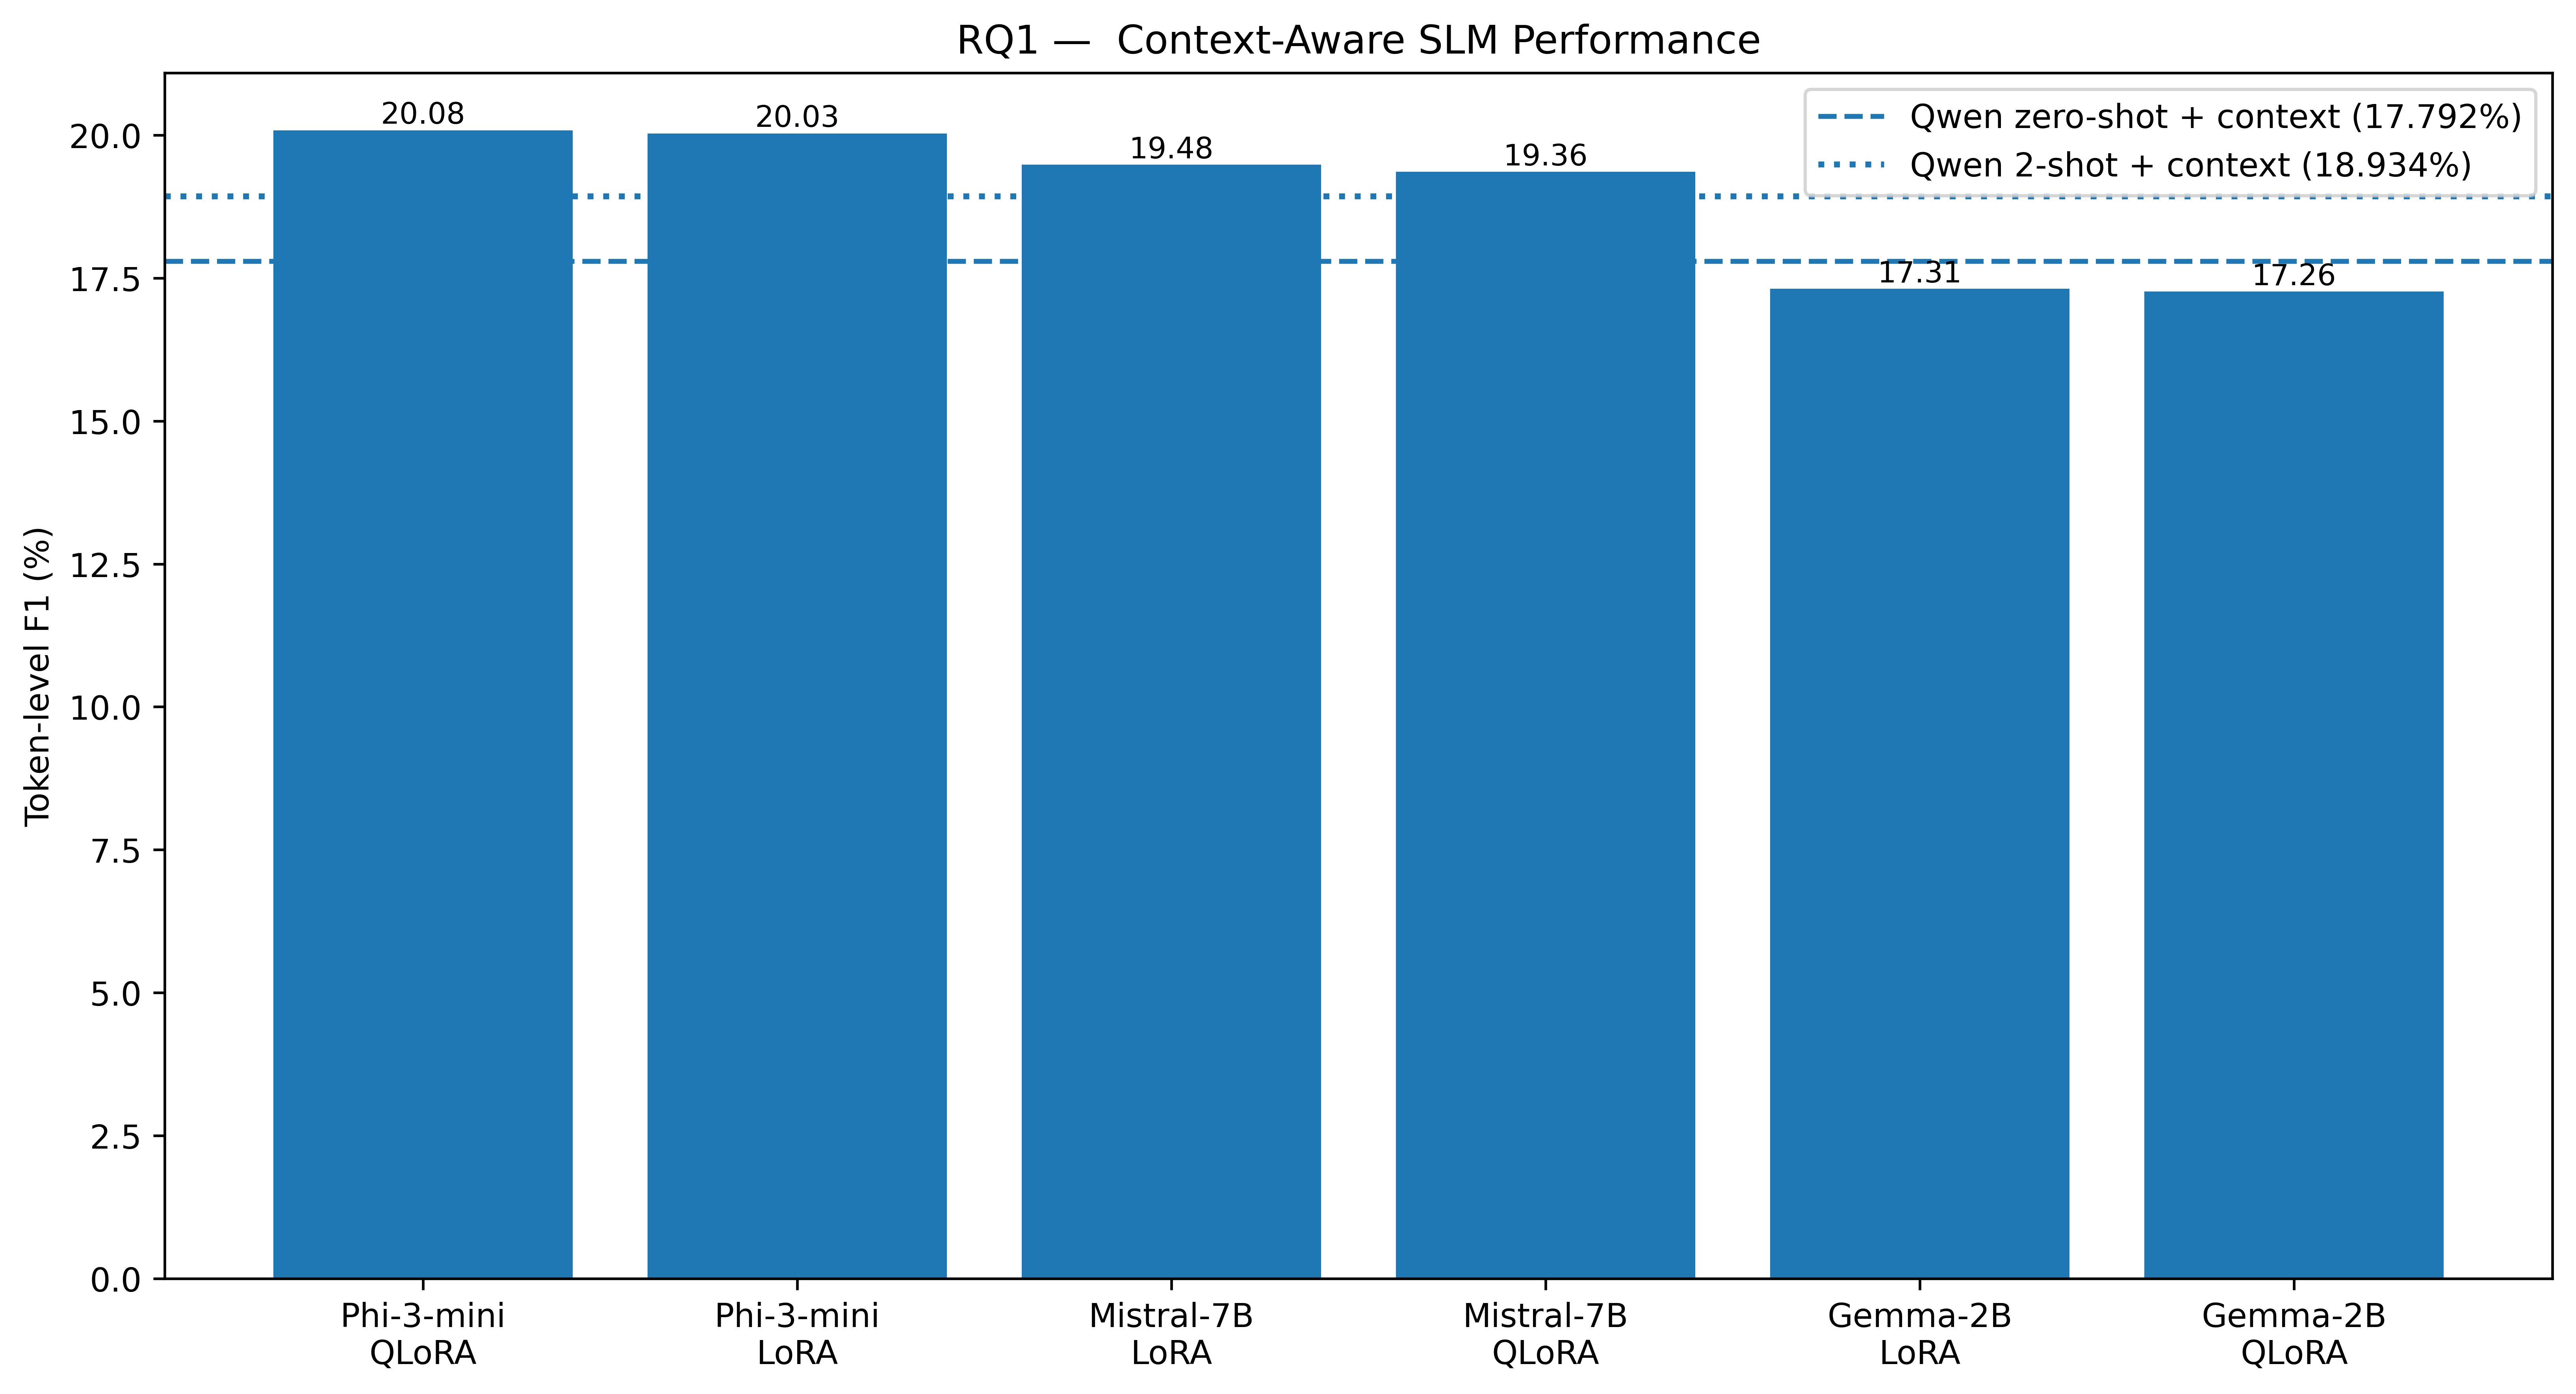

Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ1_F1_vs_Qwen_Context.png


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 6 — RQ1 FIGURE: F1 AGAINST QWEN ZERO/2-SHOT
# ═══════════════════════════════════════════════════════════

plot_df = rq1.sort_values(
    "F1_percent",
    ascending=False
).copy()

labels = (
    plot_df["Model"]
    + "\n"
    + plot_df["Method"]
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

x = np.arange(
    len(plot_df)
)

bars = ax.bar(
    x,
    plot_df["F1_percent"]
)

ax.axhline(
    QWEN_ZERO_F1,
    linestyle="--",
    linewidth=1.5,
    label=f"Qwen zero-shot + context ({QWEN_ZERO_F1:.3f}%)"
)

ax.axhline(
    QWEN_TWO_F1,
    linestyle=":",
    linewidth=1.8,
    label=f"Qwen 2-shot + context ({QWEN_TWO_F1:.3f}%)"
)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Token-level F1 (%)")
ax.set_title(
    "RQ1 —  Context-Aware SLM Performance"
)

for bar, value in zip(
    bars,
    plot_df["F1_percent"]
):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.12,
        f"{value:.2f}",
        ha="center",
        fontsize=9
    )

ax.legend()
plt.tight_layout()

RQ1_FIG = (
    f"{FIGURE_DIR}/"
    "RQ1_F1_vs_Qwen_Context.png"
)

plt.savefig(
    RQ1_FIG,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", RQ1_FIG)

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 7 — LOAD + VALIDATE RQ2 QUESTION-TYPE RESULTS
# ═══════════════════════════════════════════════════════════

rq2_files = {
    "Gemma-2B":
        "Gemma2B_CONTEXT_RQ2_QuestionType_Results.csv",
    "Phi-3-mini":
        "Phi3Mini_CONTEXT_RQ2_QuestionType_Results.csv",
    "Mistral-7B":
        "Mistral7B_CONTEXT_RQ2_QuestionType_Results.csv"
}

expected_types = {
    "multi factual",
    "multi reasoning",
    "no answer",
    "single factual",
    "single reasoning",
    "summarization",
    "yes/no"
}

rq2_frames = []

for model, filename in rq2_files.items():

    df = pd.read_csv(
        f"{RESULTS_DIR}/{filename}"
    )

    df["Question_Type"] = (
        df["Question_Type"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    assert len(df) == 7, (
        f"{model}: expected 7 question types; found {len(df)}."
    )

    assert expected_types == set(df["Question_Type"]), (
        f"{model}: native question types do not match expected SyllabusQA types."
    )

    required_cols = {
        "LoRA_F1_percent",
        "QLoRA_F1_percent",
        "Delta_F1_LoRA_minus_QLoRA"
    }

    assert required_cols.issubset(df.columns), (
        f"{model}: missing RQ2 columns: "
        f"{required_cols - set(df.columns)}"
    )

    df["Model"] = model

    rq2_frames.append(df)

rq2_all = pd.concat(
    rq2_frames,
    ignore_index=True
)

assert len(rq2_all) == 21

rq2_all["Absolute_Delta_F1"] = (
    rq2_all[
        "Delta_F1_LoRA_minus_QLoRA"
    ].abs()
)

rq2_all.to_csv(
    f"{FINAL_DIR}/RQ2_All_Models_Native_QuestionTypes.csv",
    index=False
)

print("=" * 84)
print("RQ2 — ALL THREE MODELS / SEVEN NATIVE QUESTION TYPES")
print("=" * 84)

display(
    rq2_all[
        [
            "Model",
            "Question_Type",
            "N",
            "LoRA_F1_percent",
            "QLoRA_F1_percent",
            "Delta_F1_LoRA_minus_QLoRA"
        ]
    ].round(3)
)

print("\n✓ 21 model × question-type rows validated.")

RQ2 — ALL THREE MODELS / SEVEN NATIVE QUESTION TYPES


,Model,Question_Type,N,LoRA_F1_percent,QLoRA_F1_percent,Delta_F1_LoRA_minus_QLoRA
0,Gemma-2B,multi factual,158,27.368,26.985,0.383
1,Gemma-2B,multi reasoning,158,24.892,24.800,0.091
2,Gemma-2B,no answer,155,2.811,3.098,-0.288
3,Gemma-2B,single factual,158,15.743,16.395,-0.652
4,Gemma-2B,single reasoning,158,21.509,20.876,0.632
5,Gemma-2B,summarization,158,25.771,25.288,0.483
6,Gemma-2B,yes/no,158,2.796,3.126,-0.330
7,Phi-3-mini,multi factual,158,32.365,31.142,1.222
8,Phi-3-mini,multi reasoning,158,27.673,29.035,-1.362
9,Phi-3-mini,no answer,155,4.881,3.292,1.589



✓ 21 model × question-type rows validated.


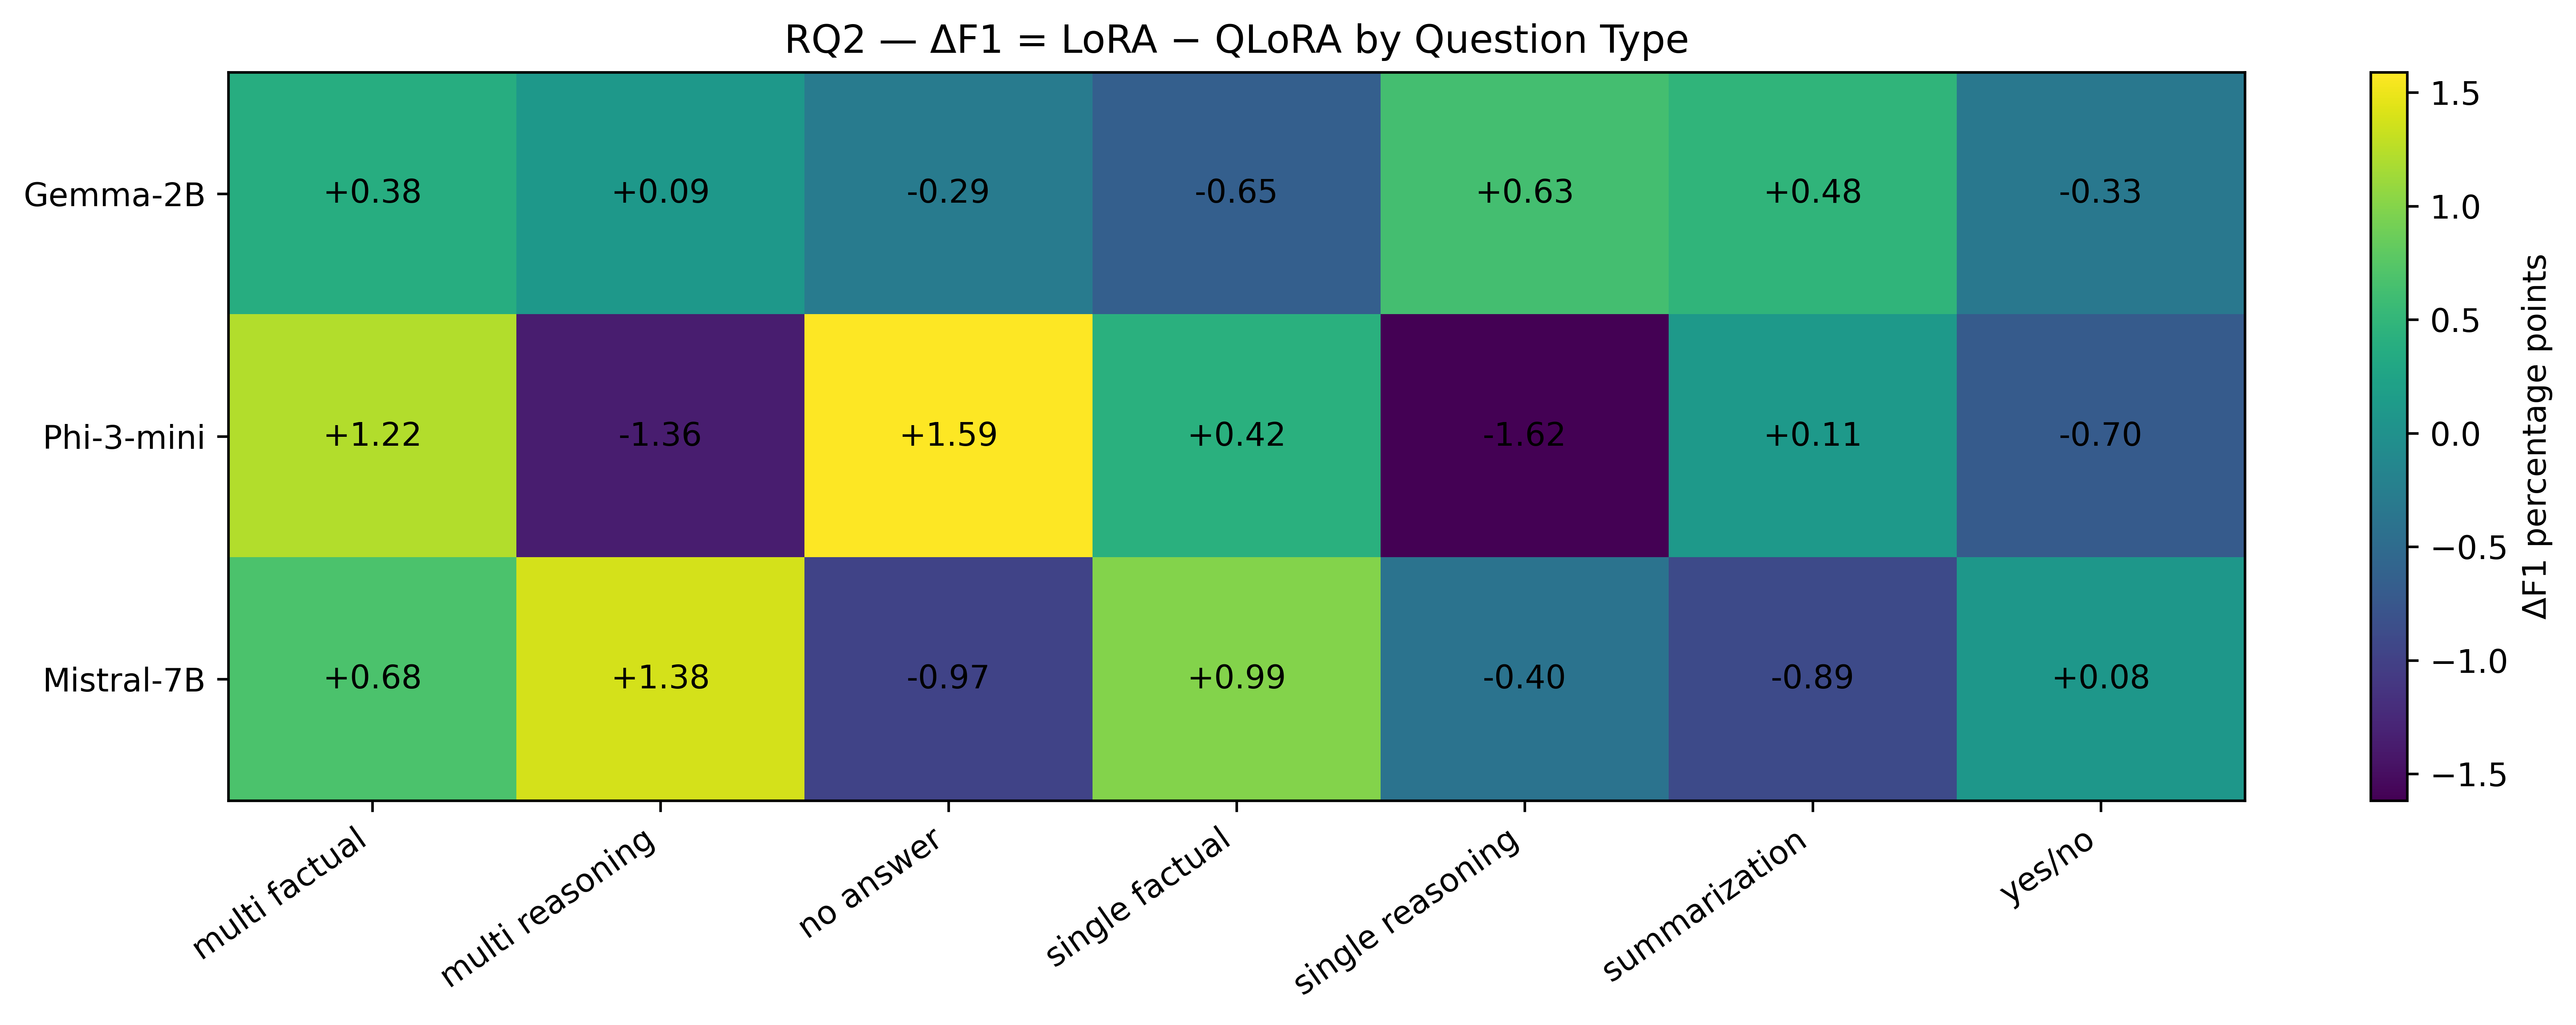

Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ2_DeltaF1_Heatmap.png


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 8 — RQ2 DELTA-F1 HEATMAP
# Positive = LoRA higher; negative = QLoRA higher.
# ═══════════════════════════════════════════════════════════

type_order = [
    "multi factual",
    "multi reasoning",
    "no answer",
    "single factual",
    "single reasoning",
    "summarization",
    "yes/no"
]

model_order = [
    "Gemma-2B",
    "Phi-3-mini",
    "Mistral-7B"
]

heat = (
    rq2_all.pivot(
        index="Model",
        columns="Question_Type",
        values="Delta_F1_LoRA_minus_QLoRA"
    )
    .reindex(
        index=model_order,
        columns=type_order
    )
)

fig, ax = plt.subplots(
    figsize=(12, 4.5)
)

im = ax.imshow(
    heat.values,
    aspect="auto"
)

ax.set_xticks(
    np.arange(
        len(type_order)
    )
)

ax.set_xticklabels(
    type_order,
    rotation=35,
    ha="right"
)

ax.set_yticks(
    np.arange(
        len(model_order)
    )
)

ax.set_yticklabels(
    model_order
)

ax.set_title(
    "RQ2 — ΔF1 = LoRA − QLoRA by Question Type"
)

for i in range(
    len(model_order)
):
    for j in range(
        len(type_order)
    ):
        ax.text(
            j,
            i,
            f"{heat.iloc[i, j]:+.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    im,
    ax=ax,
    label="ΔF1 percentage points"
)

plt.tight_layout()

RQ2_HEAT = (
    f"{FIGURE_DIR}/"
    "RQ2_DeltaF1_Heatmap.png"
)

plt.savefig(
    RQ2_HEAT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", RQ2_HEAT)

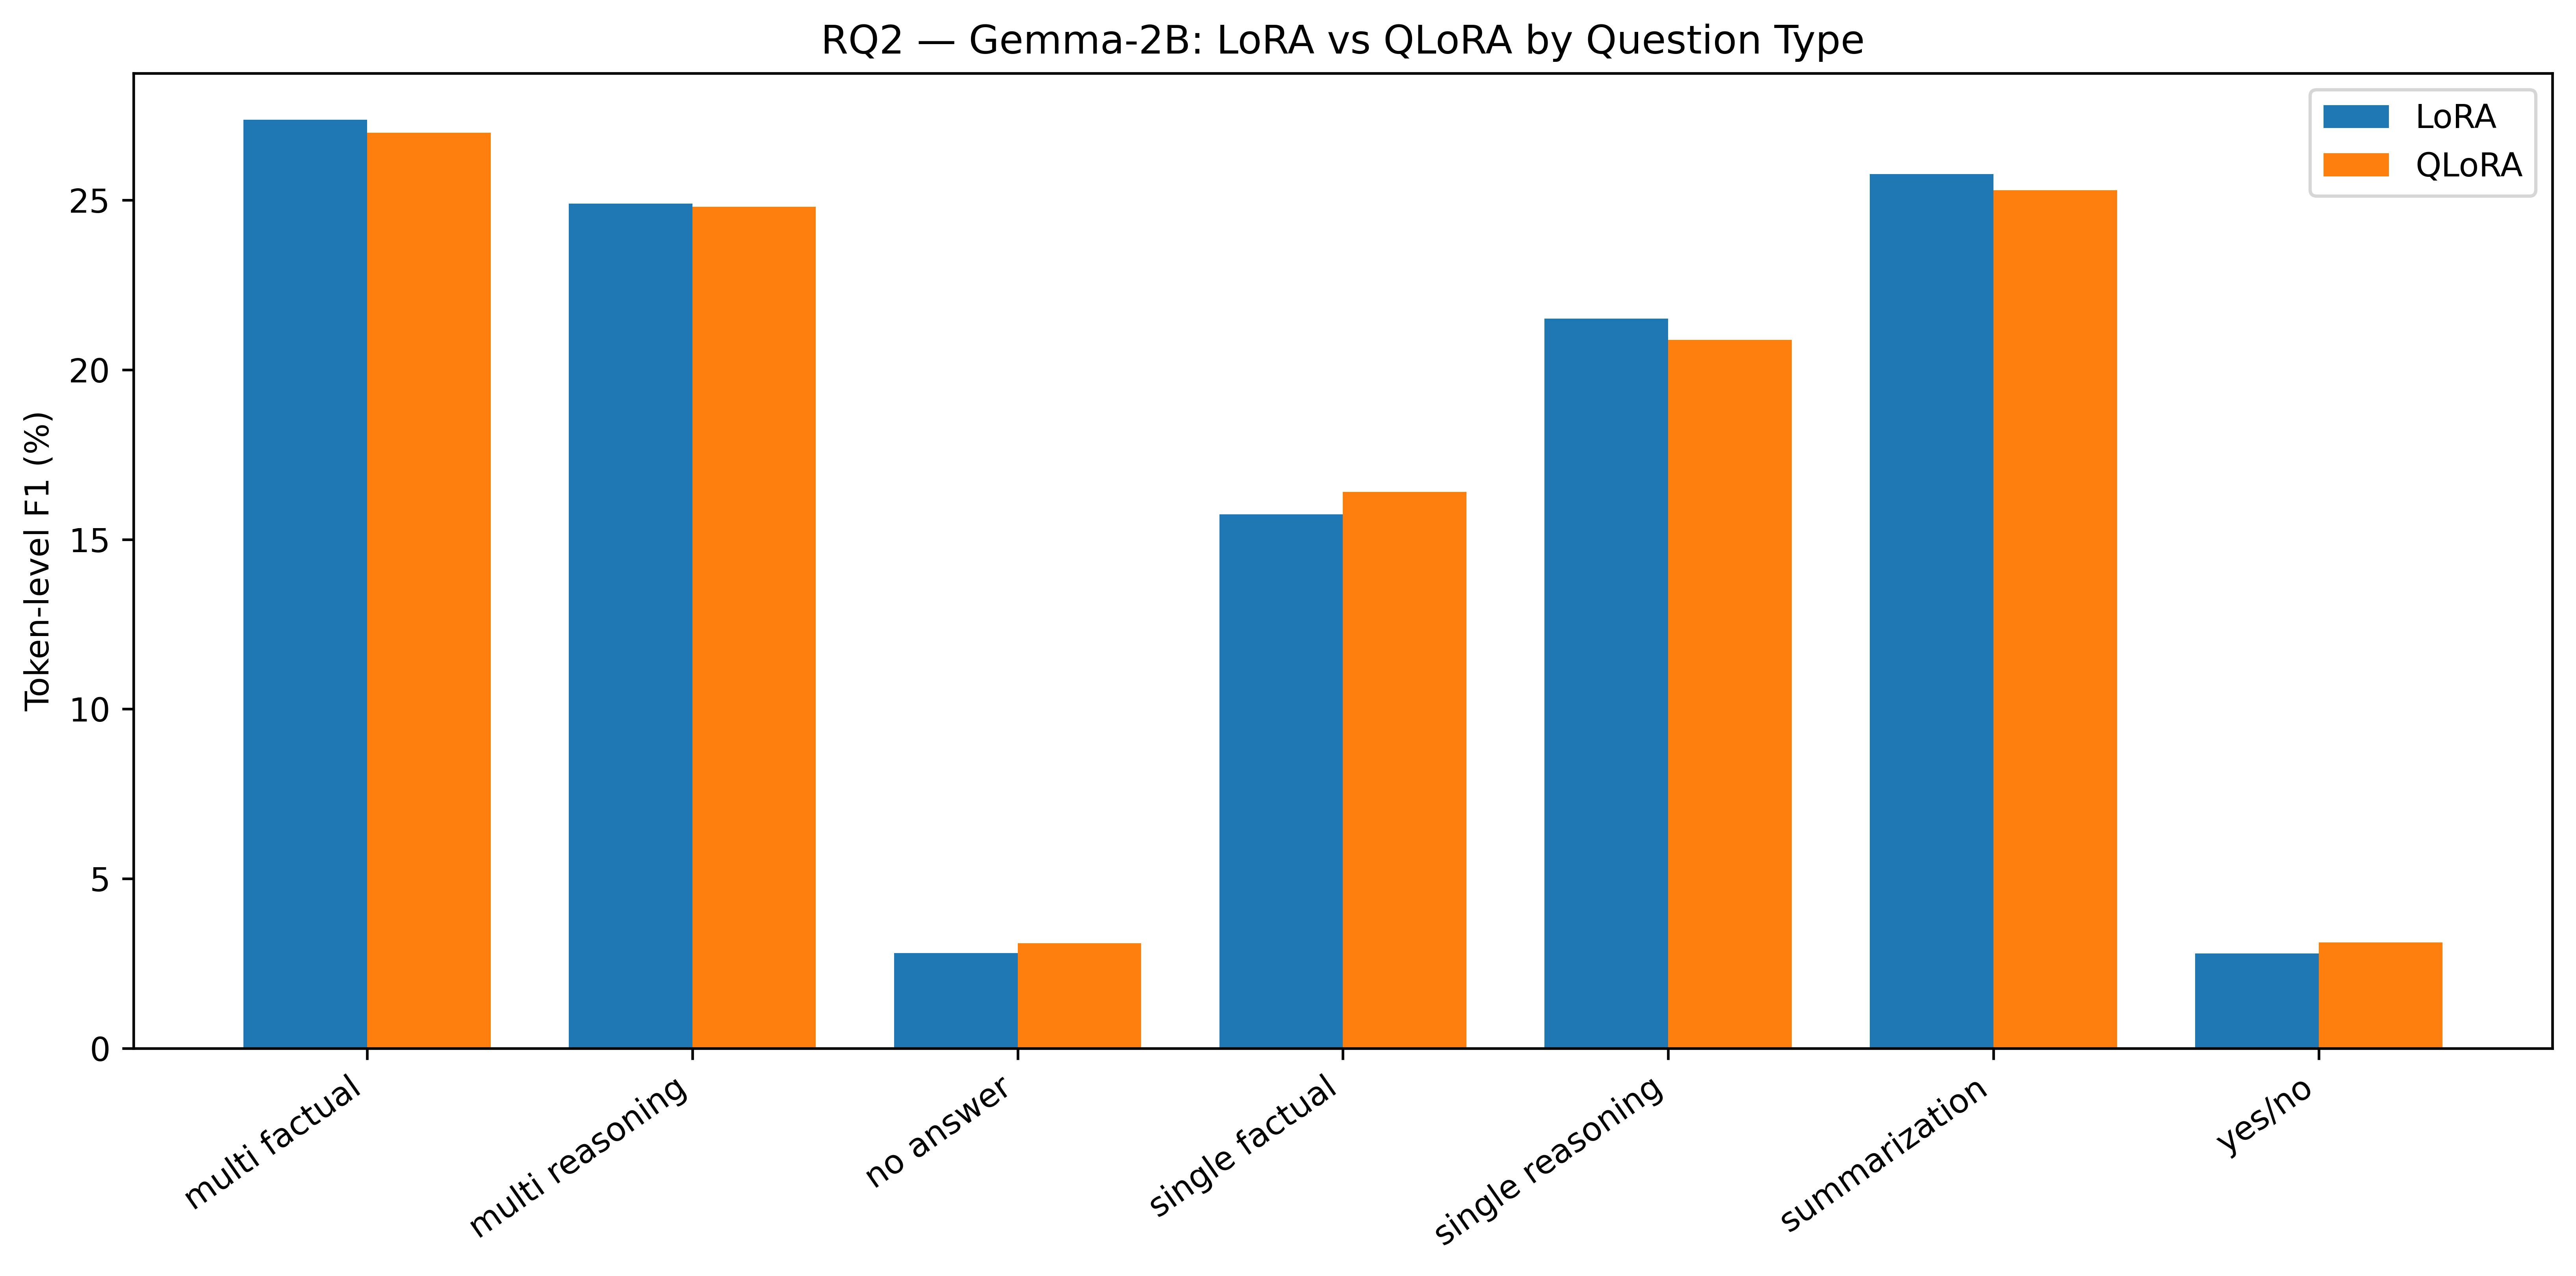

Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ2_Gemma_2B_F1.png


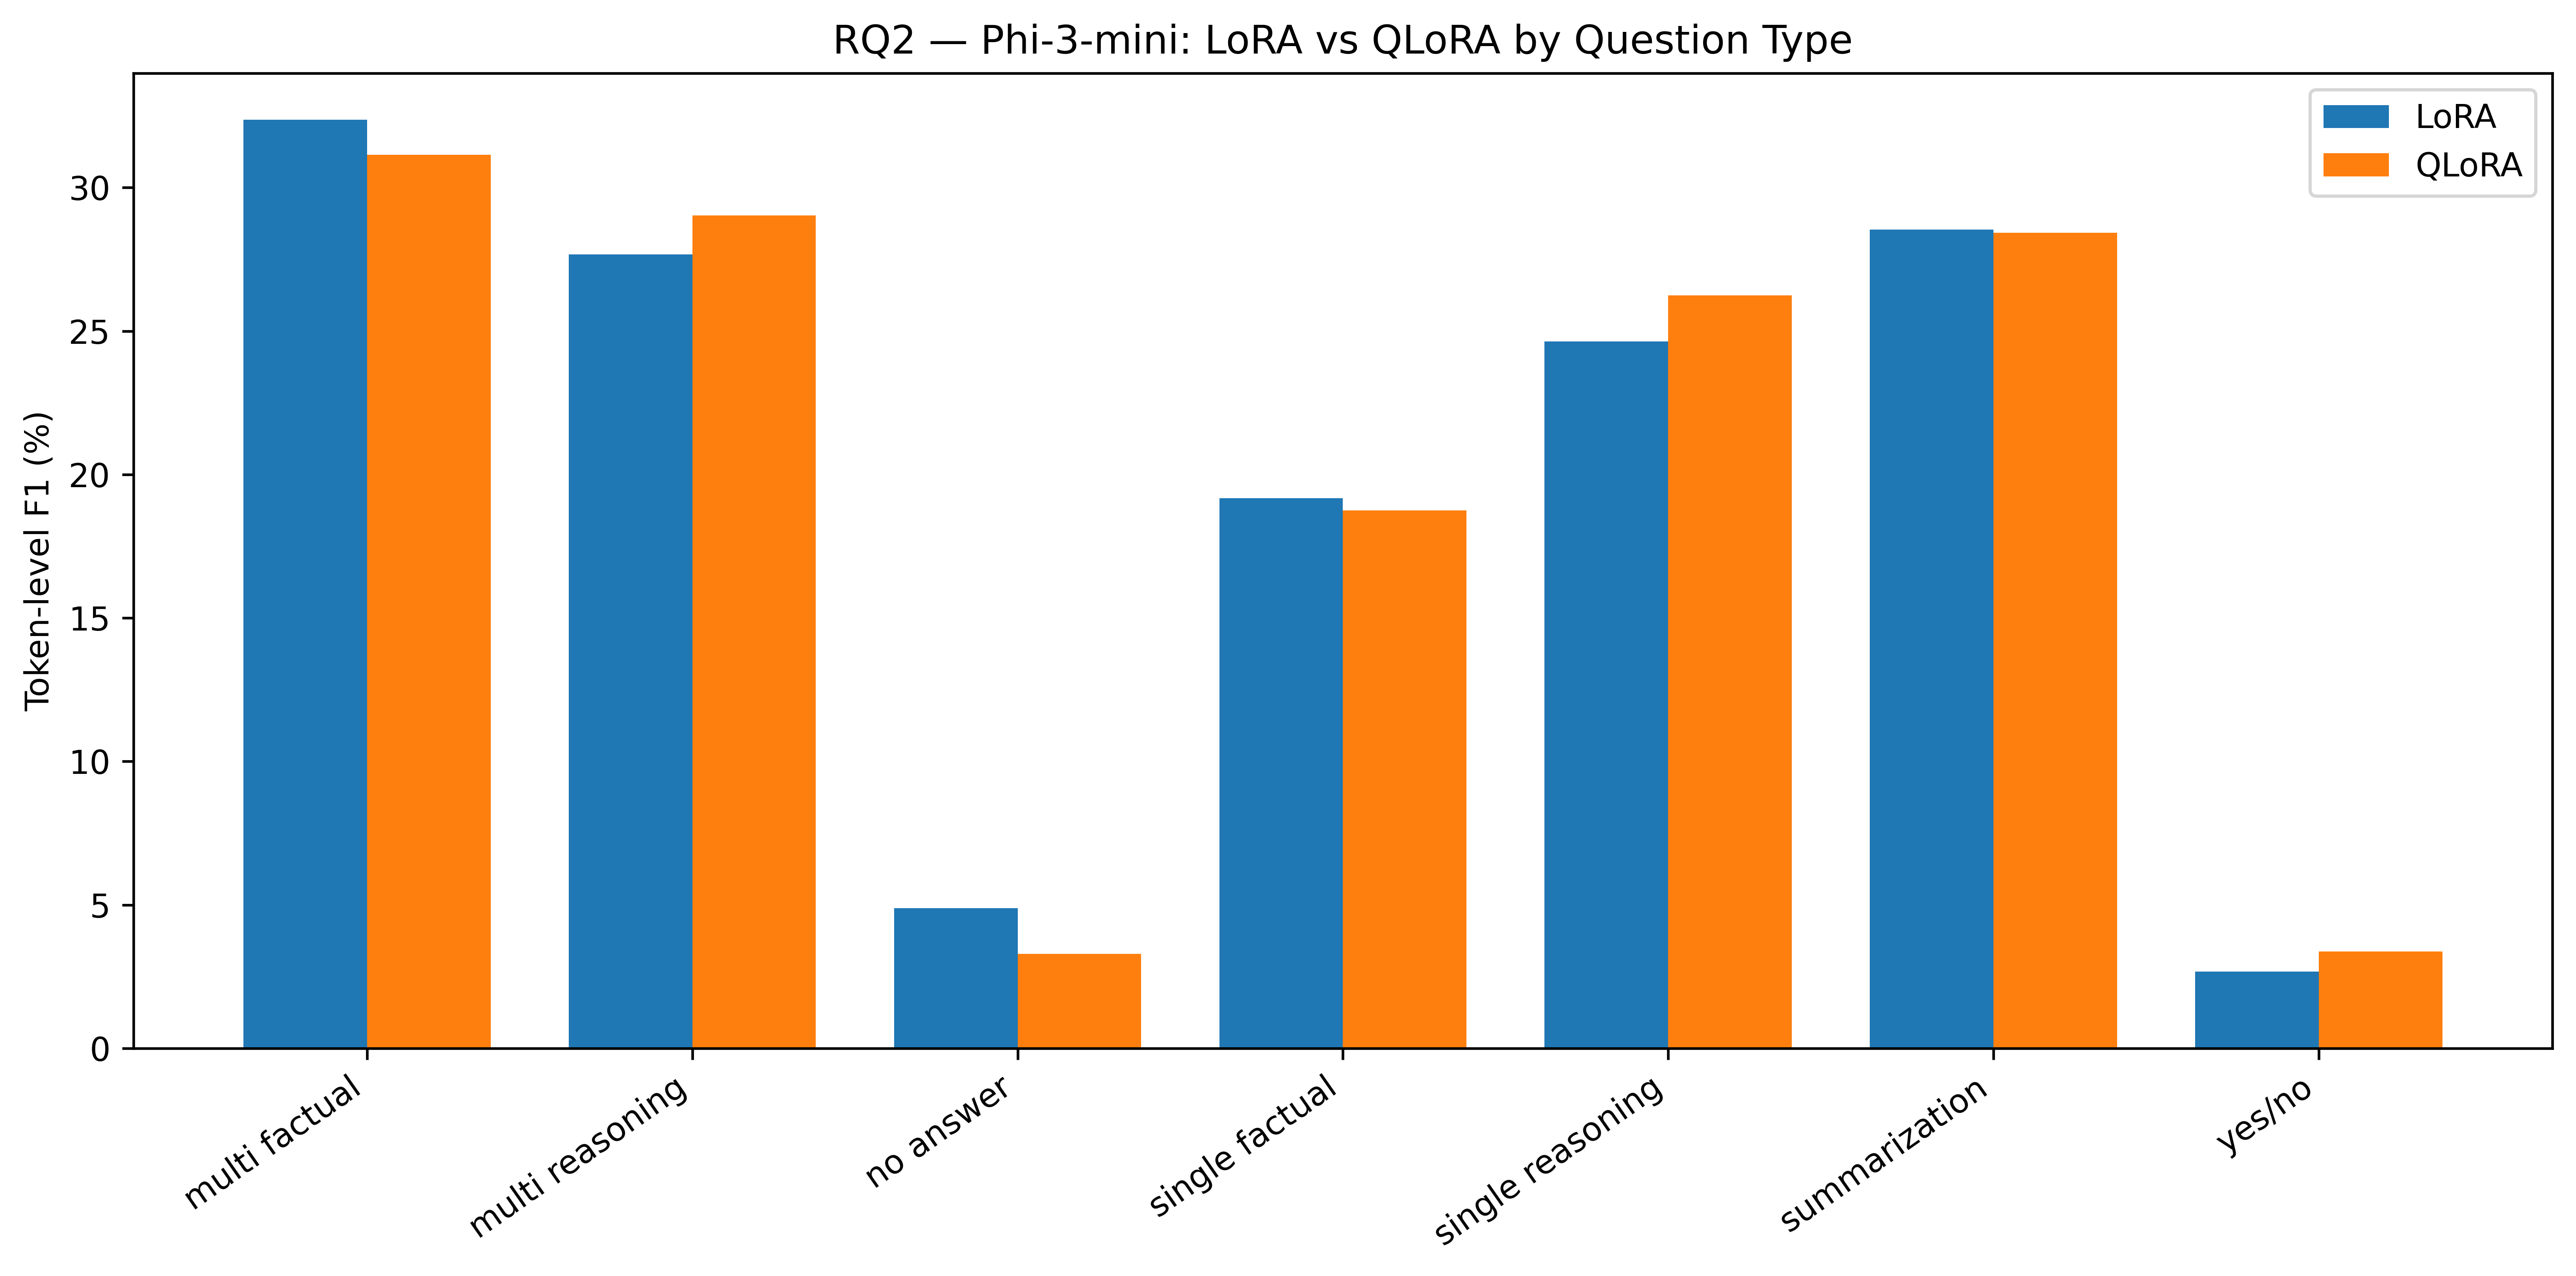

Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ2_Phi_3_mini_F1.png


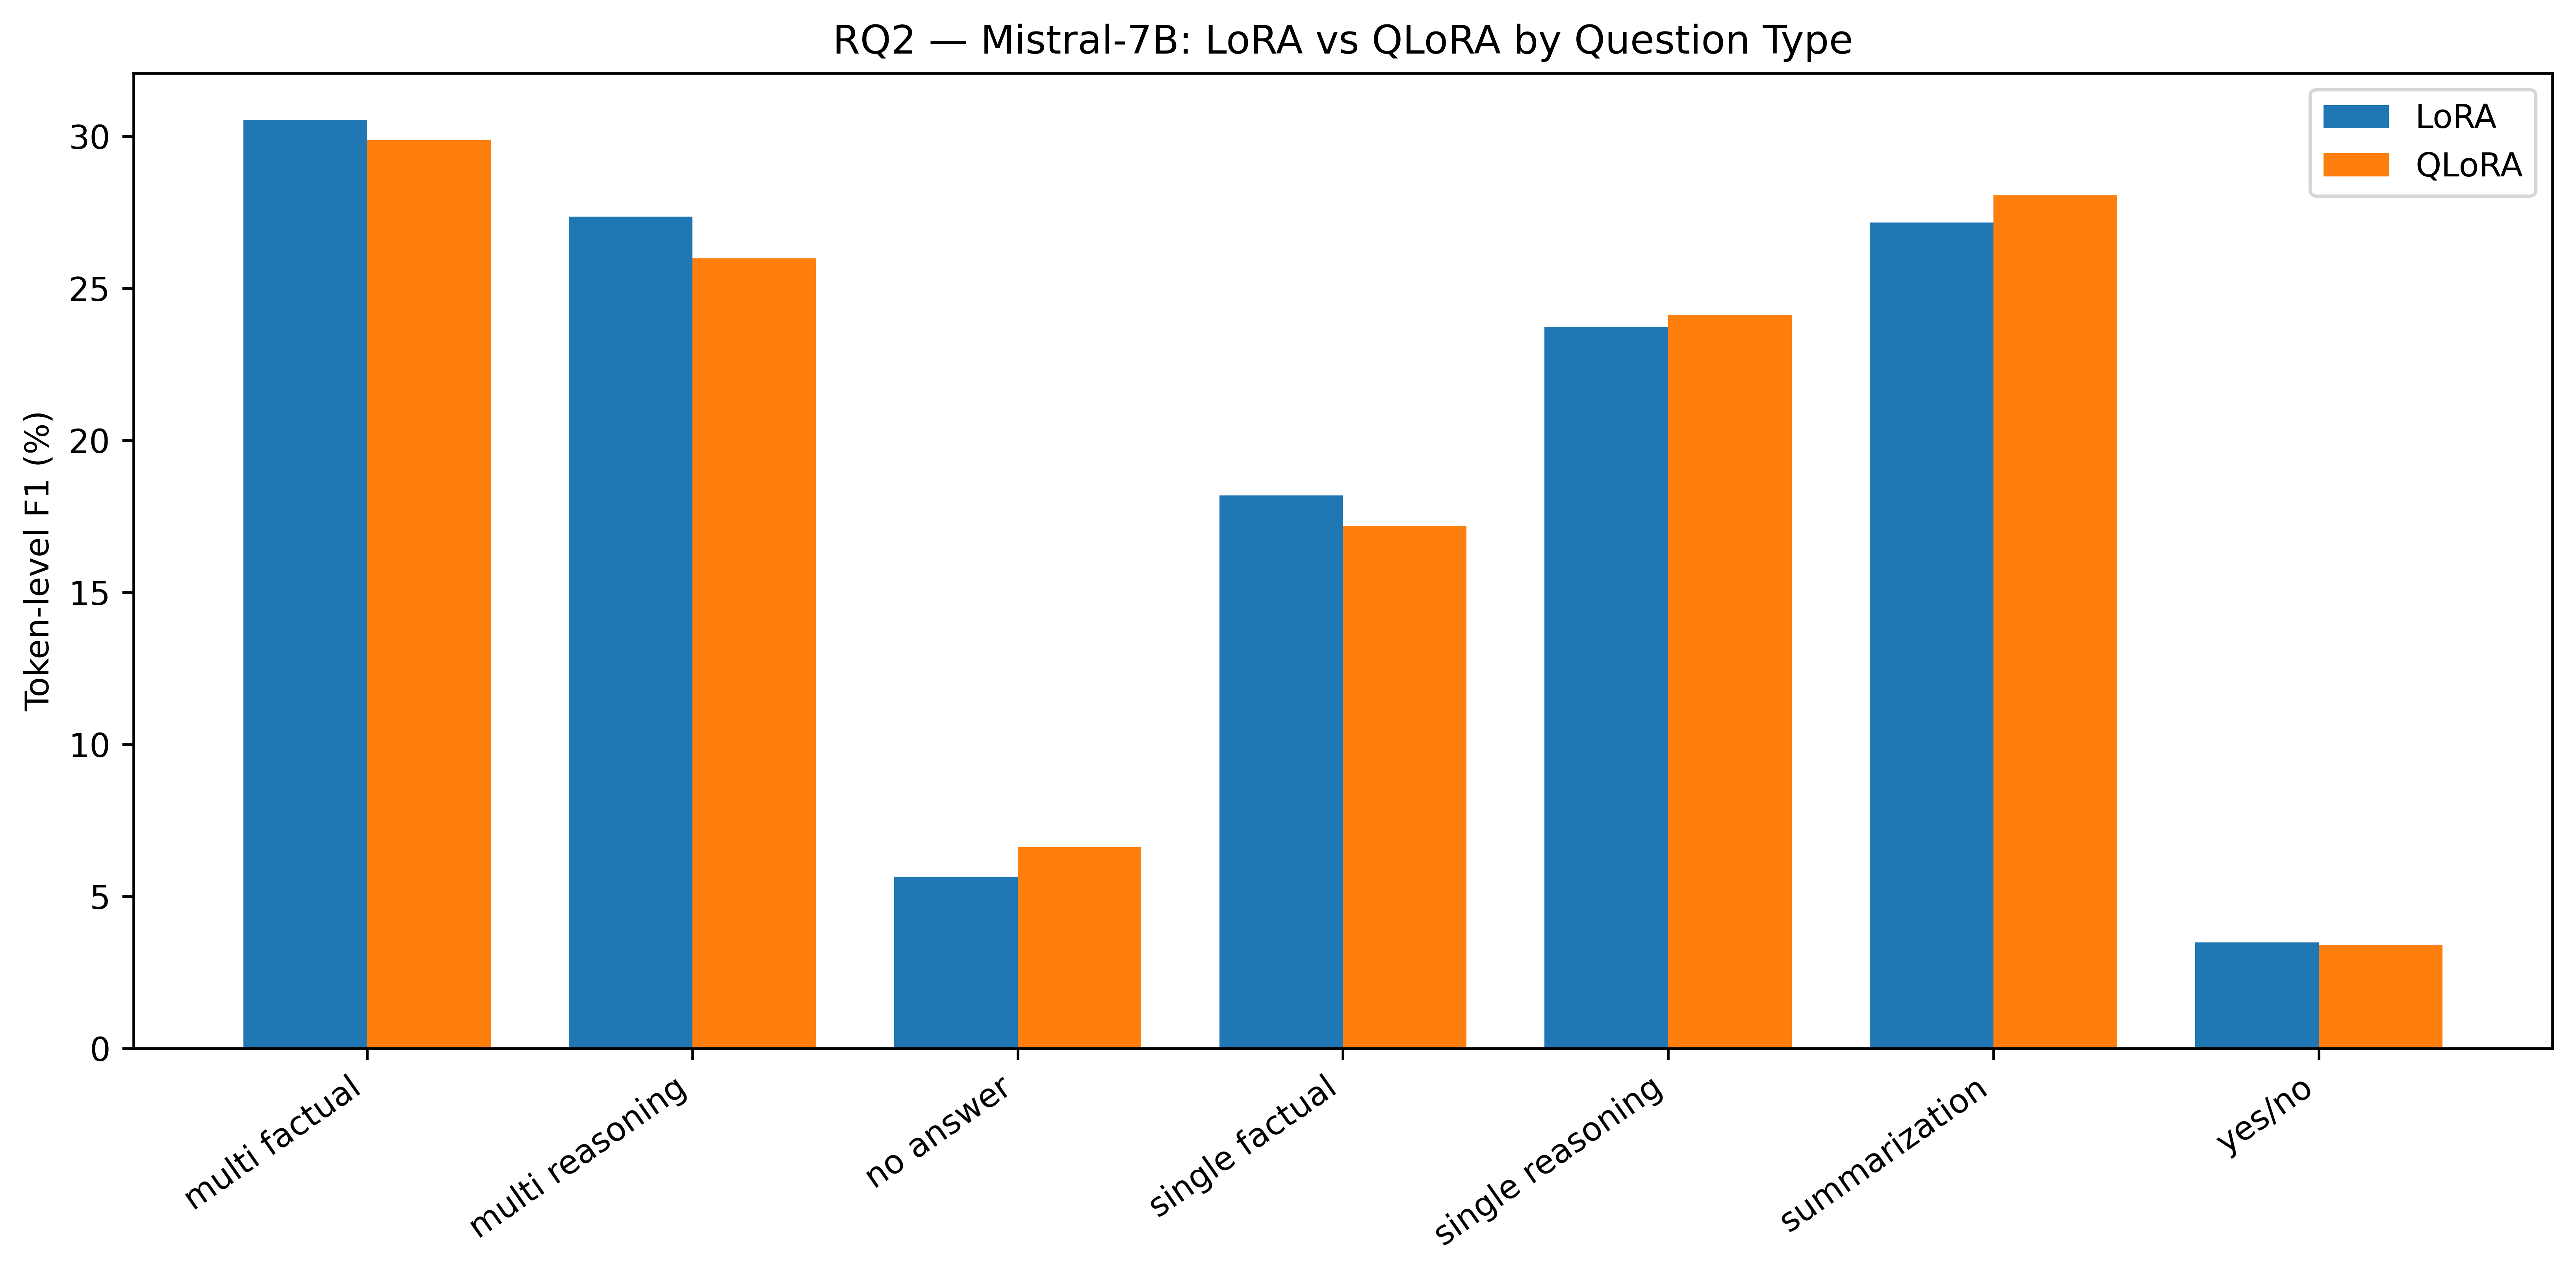

Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ2_Mistral_7B_F1.png


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 9 — RQ2 PER-MODEL QUESTION-TYPE FIGURES
# ═══════════════════════════════════════════════════════════

for model in model_order:

    d = (
        rq2_all[
            rq2_all["Model"] == model
        ]
        .set_index("Question_Type")
        .reindex(type_order)
        .reset_index()
    )

    x = np.arange(
        len(d)
    )

    width = 0.38

    fig, ax = plt.subplots(
        figsize=(11, 5.5)
    )

    ax.bar(
        x - width/2,
        d["LoRA_F1_percent"],
        width,
        label="LoRA"
    )

    ax.bar(
        x + width/2,
        d["QLoRA_F1_percent"],
        width,
        label="QLoRA"
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        d["Question_Type"],
        rotation=35,
        ha="right"
    )

    ax.set_ylabel("Token-level F1 (%)")

    ax.set_title(
        f"RQ2 — {model}: LoRA vs QLoRA by Question Type"
    )

    ax.legend()

    plt.tight_layout()

    safe_name = (
        model
        .replace("-", "_")
        .replace(" ", "_")
    )

    figure_path = (
        f"{FIGURE_DIR}/"
        f"RQ2_{safe_name}_F1.png"
    )

    plt.savefig(
        figure_path,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", figure_path)

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 10 — RQ2 SUMMARY: MAGNITUDE + MODEL-LEVEL EFFECTS
# ═══════════════════════════════════════════════════════════

rq2_ranked = rq2_all.sort_values(
    "Absolute_Delta_F1",
    ascending=False
).reset_index(drop=True)

print("=" * 84)
print("RQ2 — LARGEST ABSOLUTE LoRA/QLoRA QUESTION-TYPE DIFFERENCES")
print("=" * 84)

display(
    rq2_ranked[
        [
            "Model",
            "Question_Type",
            "LoRA_F1_percent",
            "QLoRA_F1_percent",
            "Delta_F1_LoRA_minus_QLoRA",
            "Absolute_Delta_F1"
        ]
    ].head(10).round(3)
)

rq2_model_summary = (
    rq2_all.groupby("Model", as_index=False)
    .agg(
        Mean_LoRA_F1=("LoRA_F1_percent", "mean"),
        Mean_QLoRA_F1=("QLoRA_F1_percent", "mean"),
        Mean_Delta_F1=(
            "Delta_F1_LoRA_minus_QLoRA",
            "mean"
        ),
        Mean_Absolute_Delta_F1=(
            "Absolute_Delta_F1",
            "mean"
        ),
        Max_Absolute_Delta_F1=(
            "Absolute_Delta_F1",
            "max"
        )
    )
)

print("\nModel-level RQ2 summary:")

display(
    rq2_model_summary.round(3)
)

rq2_model_summary.to_csv(
    f"{FINAL_DIR}/RQ2_Model_Level_Summary.csv",
    index=False
)

RQ2 — LARGEST ABSOLUTE LoRA/QLoRA QUESTION-TYPE DIFFERENCES


,Model,Question_Type,LoRA_F1_percent,QLoRA_F1_percent,Delta_F1_LoRA_minus_QLoRA,Absolute_Delta_F1
0,Phi-3-mini,single reasoning,24.631,26.249,-1.617,1.617
1,Phi-3-mini,no answer,4.881,3.292,1.589,1.589
2,Mistral-7B,multi reasoning,27.359,25.982,1.377,1.377
3,Phi-3-mini,multi reasoning,27.673,29.035,-1.362,1.362
4,Phi-3-mini,multi factual,32.365,31.142,1.222,1.222
5,Mistral-7B,single factual,18.188,17.193,0.995,0.995
6,Mistral-7B,no answer,5.646,6.619,-0.973,0.973
7,Mistral-7B,summarization,27.160,28.055,-0.895,0.895
8,Phi-3-mini,yes/no,2.676,3.374,-0.699,0.699
9,Mistral-7B,multi factual,30.545,29.867,0.678,0.678



Model-level RQ2 summary:


,Model,Mean_LoRA_F1,Mean_QLoRA_F1,Mean_Delta_F1,Mean_Absolute_Delta_F1,Max_Absolute_Delta_F1
0,Gemma-2B,17.270,17.224,0.046,0.408,0.652
1,Mistral-7B,19.445,19.323,0.122,0.771,1.377
2,Phi-3-mini,19.989,20.038,-0.049,1.002,1.617


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 11 — RQ3 RAW PERFORMANCE / EFFICIENCY TABLE
# ═══════════════════════════════════════════════════════════

rq3 = all_results[
    [
        "Model",
        "Method",
        "Parameters_B",
        "F1_percent",
        "EM_percent",
        "Training_Time_min",
        "Avg_Latency_ms",
        "Peak_Eval_VRAM_GB",
        "Peak_Train_VRAM_GB"
    ]
].copy()

rq3 = rq3.sort_values(
    "F1_percent",
    ascending=False
).reset_index(drop=True)

print("=" * 84)
print("RQ3 — RAW PERFORMANCE / EFFICIENCY COMPARISON")
print("=" * 84)

display(
    rq3.round(3)
)

rq3.to_csv(
    f"{FINAL_DIR}/RQ3_Raw_Comparison.csv",
    index=False
)

RQ3 — RAW PERFORMANCE / EFFICIENCY COMPARISON


,Model,Method,Parameters_B,F1_percent,EM_percent,Training_Time_min,Avg_Latency_ms,Peak_Eval_VRAM_GB,Peak_Train_VRAM_GB
0,Phi-3-mini,QLoRA,3.8,20.084,0.000,21.845,4344.341,3.237,4.448
1,Phi-3-mini,LoRA,3.8,20.030,0.091,17.008,3555.800,7.421,8.346
2,Mistral-7B,LoRA,7.0,19.483,0.000,23.419,4117.590,13.701,14.897
3,Mistral-7B,QLoRA,7.0,19.357,0.000,31.409,6328.417,4.991,6.733
4,Gemma-2B,LoRA,2.0,17.309,0.000,11.342,2410.089,5.121,10.737
5,Gemma-2B,QLoRA,2.0,17.263,0.000,16.083,3619.289,3.321,10.092


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 12 — RQ3 PARETO ANALYSIS
# Dimensions retained from the old notebook:
#   maximize F1
#   minimize latency
#   minimize evaluation VRAM
# Training time/VRAM are descriptive, not Pareto dimensions.
# ═══════════════════════════════════════════════════════════

def is_dominated(i, df):

    a = df.loc[i]

    for j in df.index:

        if j == i:
            continue

        b = df.loc[j]

        no_worse = (
            b["F1_percent"]
            >=
            a["F1_percent"]
            and
            b["Avg_Latency_ms"]
            <=
            a["Avg_Latency_ms"]
            and
            b["Peak_Eval_VRAM_GB"]
            <=
            a["Peak_Eval_VRAM_GB"]
        )

        strictly_better = (
            b["F1_percent"]
            >
            a["F1_percent"]
            or
            b["Avg_Latency_ms"]
            <
            a["Avg_Latency_ms"]
            or
            b["Peak_Eval_VRAM_GB"]
            <
            a["Peak_Eval_VRAM_GB"]
        )

        if no_worse and strictly_better:
            return True

    return False


pareto = all_results.copy()

pareto["Dominated"] = [
    is_dominated(i, pareto)
    for i in pareto.index
]

pareto["Pareto_Efficient"] = (
    ~pareto["Dominated"]
)

pareto_view = (
    pareto[
        [
            "Model",
            "Method",
            "F1_percent",
            "Avg_Latency_ms",
            "Peak_Eval_VRAM_GB",
            "Pareto_Efficient"
        ]
    ]
    .sort_values(
        [
            "Pareto_Efficient",
            "F1_percent"
        ],
        ascending=[
            False,
            False
        ]
    )
)

print("=" * 84)
print("RQ3 — PARETO EFFICIENCY")
print("=" * 84)

display(
    pareto_view.round(3)
)

pareto_view.to_csv(
    f"{FINAL_DIR}/RQ3_Pareto_Analysis.csv",
    index=False
)

RQ3 — PARETO EFFICIENCY


,Model,Method,F1_percent,Avg_Latency_ms,Peak_Eval_VRAM_GB,Pareto_Efficient
3,Phi-3-mini,QLoRA,20.084,4344.341,3.237,True
2,Phi-3-mini,LoRA,20.030,3555.800,7.421,True
0,Gemma-2B,LoRA,17.309,2410.089,5.121,True
1,Gemma-2B,QLoRA,17.263,3619.289,3.321,True
4,Mistral-7B,LoRA,19.483,4117.590,13.701,False
5,Mistral-7B,QLoRA,19.357,6328.417,4.991,False


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 13 — SECONDARY 50/25/25 DEPLOYMENT COMPOSITE
# Same formula as the old cross-comparison notebook.
# This is a decision aid, not a universal optimum.
# ═══════════════════════════════════════════════════════════

def benefit_norm(series):

    s = pd.to_numeric(series)

    if s.max() == s.min():
        return pd.Series(
            np.ones(len(s)),
            index=s.index
        )

    return (
        s - s.min()
    ) / (
        s.max() - s.min()
    )


def cost_norm(series):

    s = pd.to_numeric(series)

    if s.max() == s.min():
        return pd.Series(
            np.ones(len(s)),
            index=s.index
        )

    return (
        s.max() - s
    ) / (
        s.max() - s.min()
    )


score = all_results.copy()

score["F1_Norm"] = benefit_norm(
    score["F1_percent"]
)

score["Latency_Efficiency"] = cost_norm(
    score["Avg_Latency_ms"]
)

score["Eval_VRAM_Efficiency"] = cost_norm(
    score["Peak_Eval_VRAM_GB"]
)

score["Deployment_Composite_Score"] = 100 * (
    0.50 * score["F1_Norm"]
    +
    0.25 * score["Latency_Efficiency"]
    +
    0.25 * score["Eval_VRAM_Efficiency"]
)

score = score.sort_values(
    "Deployment_Composite_Score",
    ascending=False
).reset_index(drop=True)

score["Composite_Rank"] = (
    np.arange(
        1,
        len(score) + 1
    )
)

print("=" * 84)
print("SECONDARY DEPLOYMENT COMPOSITE — 50/25/25")
print("=" * 84)

display(
    score[
        [
            "Composite_Rank",
            "Model",
            "Method",
            "F1_percent",
            "Avg_Latency_ms",
            "Peak_Eval_VRAM_GB",
            "Deployment_Composite_Score"
        ]
    ].round(3)
)

score.to_csv(
    f"{FINAL_DIR}/RQ3_Deployment_Composite_Score.csv",
    index=False
)

print(
    "\nInterpretation: this weighted score is a secondary "
    "decision aid under the stated 50/25/25 priorities."
)

SECONDARY DEPLOYMENT COMPOSITE — 50/25/25


,Composite_Rank,Model,Method,F1_percent,Avg_Latency_ms,Peak_Eval_VRAM_GB,Deployment_Composite_Score
0,1,Phi-3-mini,QLoRA,20.084,4344.341,3.237,87.659
1,2,Phi-3-mini,LoRA,20.030,3555.800,7.421,81.746
2,3,Mistral-7B,QLoRA,19.357,6328.417,4.991,57.933
3,4,Mistral-7B,LoRA,19.483,4117.590,13.701,53.450
4,5,Gemma-2B,LoRA,17.309,2410.089,5.121,46.325
5,6,Gemma-2B,QLoRA,17.263,3619.289,3.321,42.086



Interpretation: this weighted score is a secondary decision aid under the stated 50/25/25 priorities.


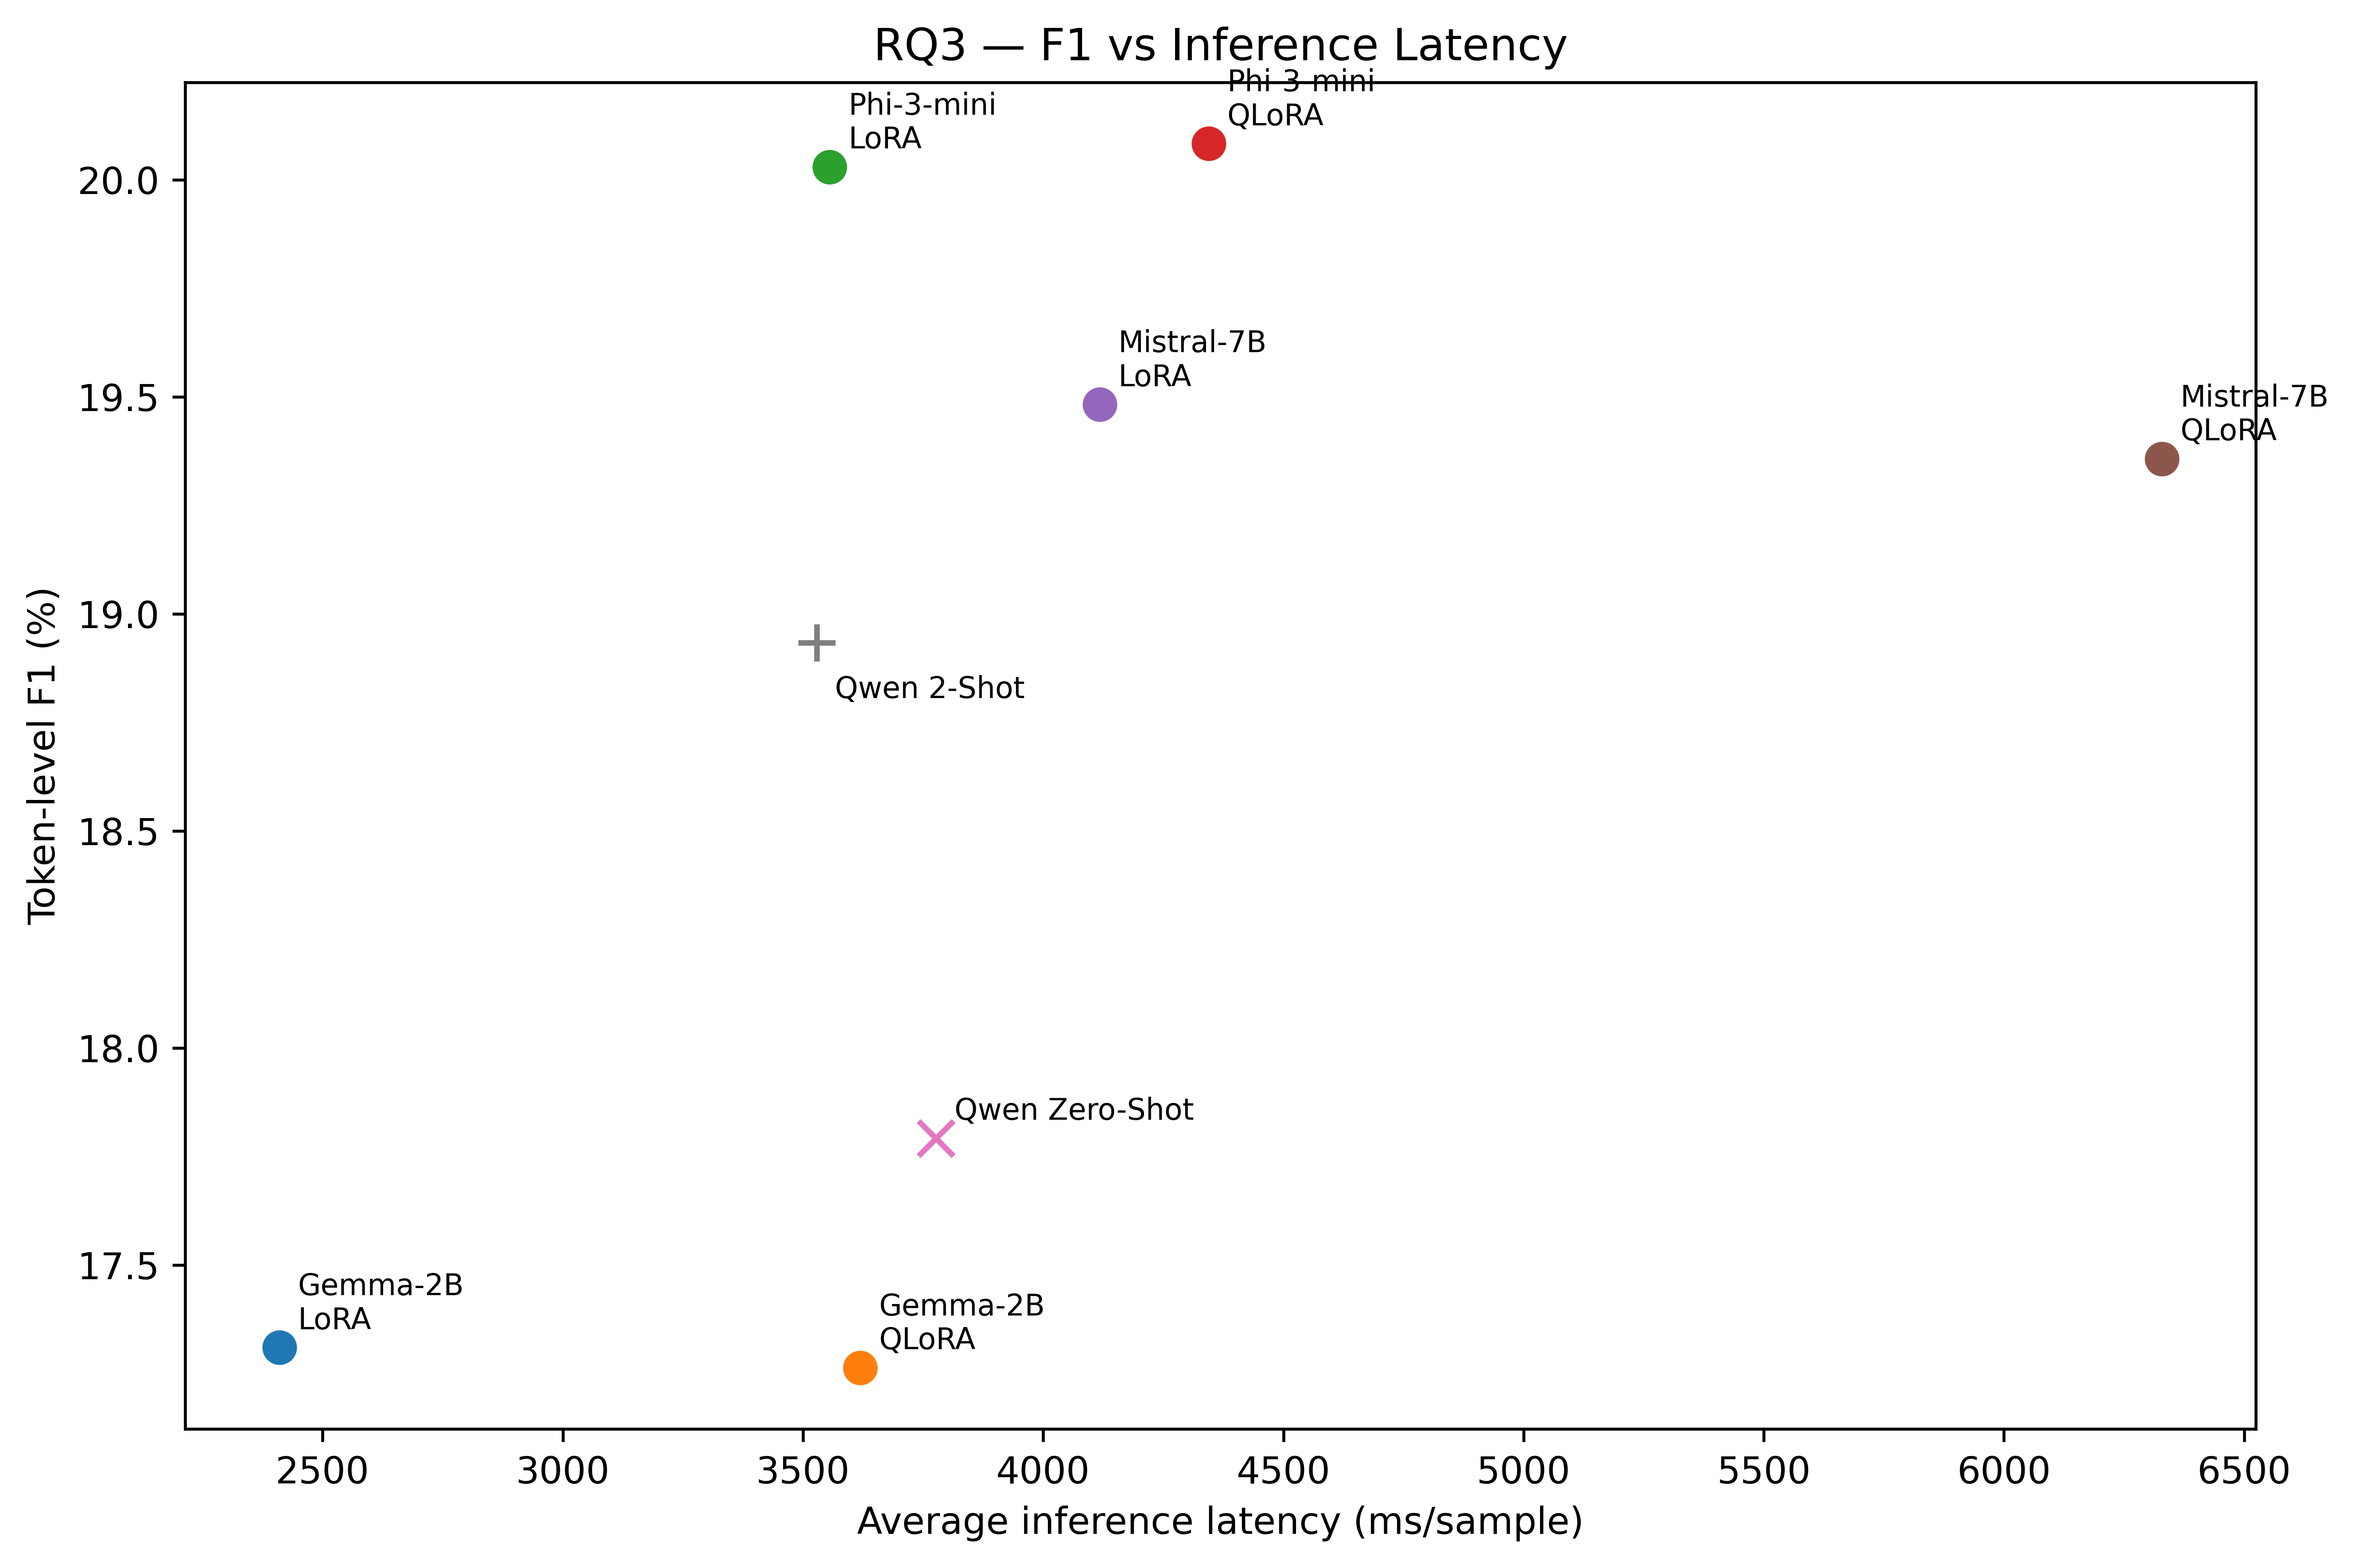

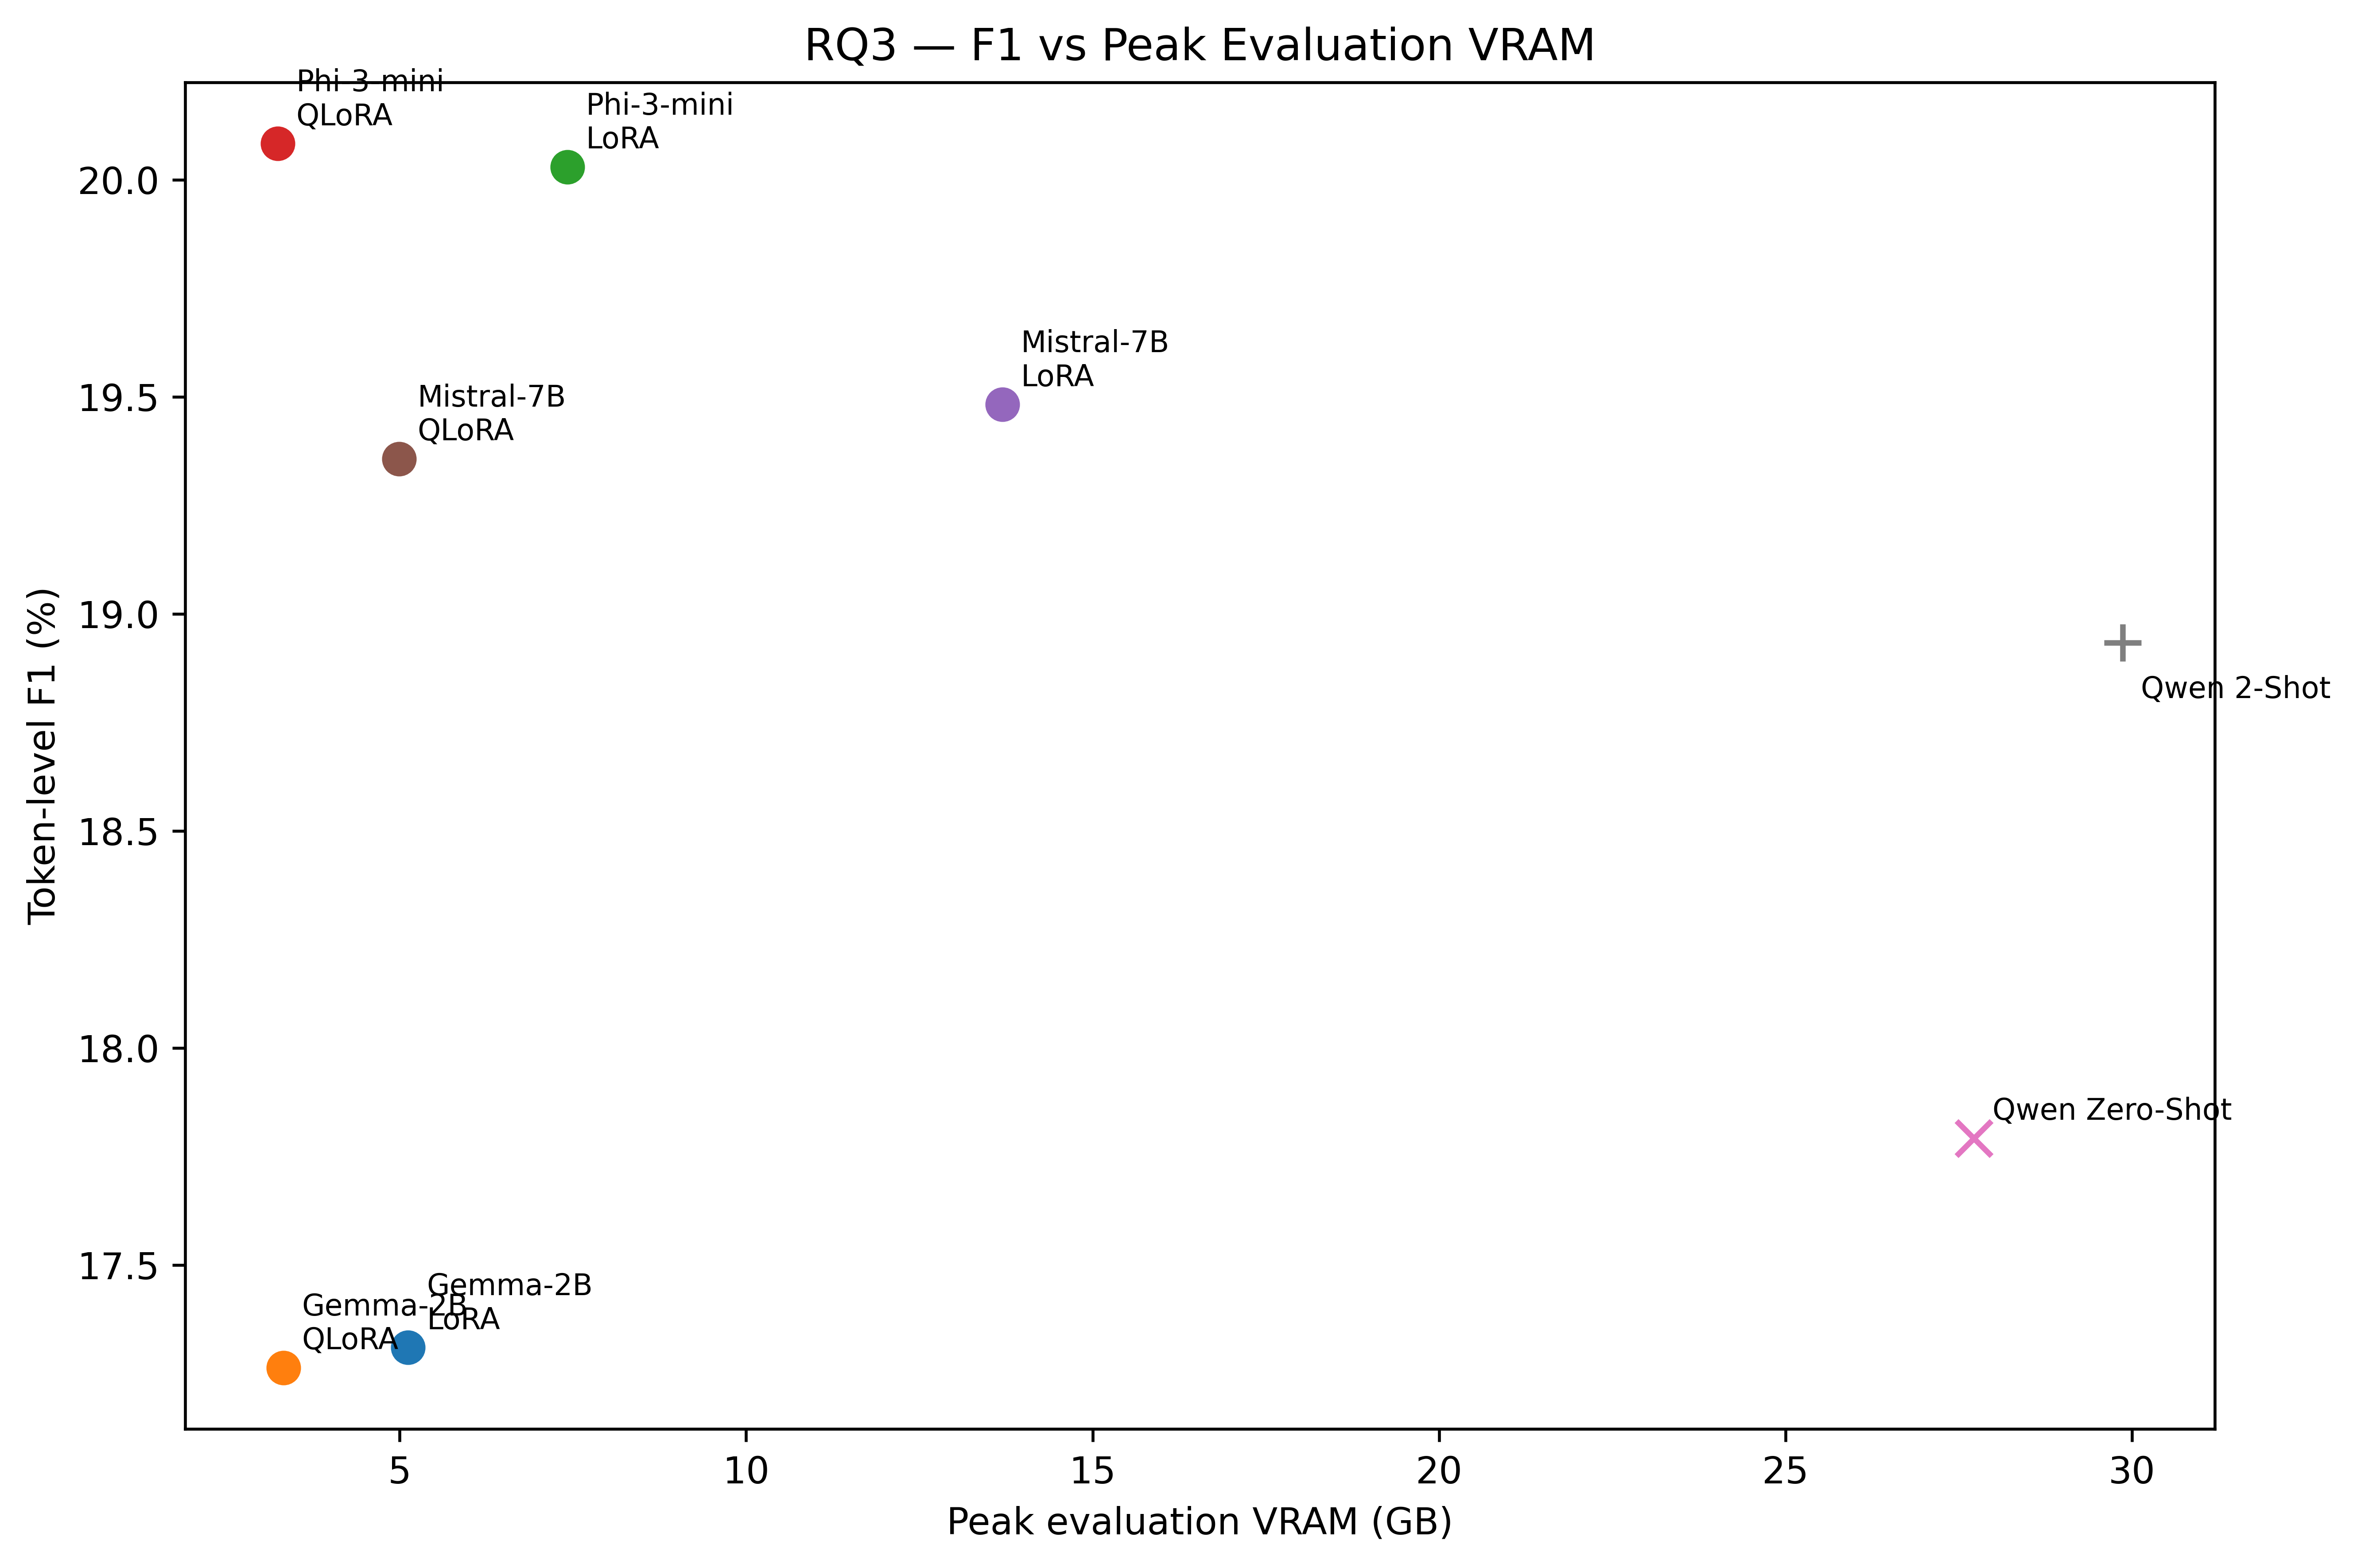

Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ3_F1_vs_Latency.png
Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ3_F1_vs_EvalVRAM.png


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 14 — RQ3 FIGURES: F1 VS LATENCY + F1 VS EVAL VRAM
# ═══════════════════════════════════════════════════════════

# F1 vs latency
fig, ax = plt.subplots(
    figsize=(9, 6)
)

for _, row in all_results.iterrows():

    ax.scatter(
        row["Avg_Latency_ms"],
        row["F1_percent"],
        s=70
    )

    ax.annotate(
        f'{row["Model"]}\n{row["Method"]}',
        (
            row["Avg_Latency_ms"],
            row["F1_percent"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.scatter(
    QWEN_ZERO_LAT,
    QWEN_ZERO_F1,
    marker="x",
    s=90
)

ax.annotate(
    "Qwen Zero-Shot",
    (
        QWEN_ZERO_LAT,
        QWEN_ZERO_F1
    ),
    xytext=(5, 5),
    textcoords="offset points",
    fontsize=8
)

ax.scatter(
    QWEN_TWO_LAT,
    QWEN_TWO_F1,
    marker="+",
    s=100
)

ax.annotate(
    "Qwen 2-Shot",
    (
        QWEN_TWO_LAT,
        QWEN_TWO_F1
    ),
    xytext=(5, -15),
    textcoords="offset points",
    fontsize=8
)

ax.set_xlabel(
    "Average inference latency (ms/sample)"
)

ax.set_ylabel(
    "Token-level F1 (%)"
)

ax.set_title(
    "RQ3 — F1 vs Inference Latency"
)

plt.tight_layout()

LAT_FIG = (
    f"{FIGURE_DIR}/"
    "RQ3_F1_vs_Latency.png"
)

plt.savefig(
    LAT_FIG,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# F1 vs evaluation VRAM
fig, ax = plt.subplots(
    figsize=(9, 6)
)

for _, row in all_results.iterrows():

    ax.scatter(
        row["Peak_Eval_VRAM_GB"],
        row["F1_percent"],
        s=70
    )

    ax.annotate(
        f'{row["Model"]}\n{row["Method"]}',
        (
            row["Peak_Eval_VRAM_GB"],
            row["F1_percent"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.scatter(
    QWEN_ZERO_VRAM,
    QWEN_ZERO_F1,
    marker="x",
    s=90
)

ax.annotate(
    "Qwen Zero-Shot",
    (
        QWEN_ZERO_VRAM,
        QWEN_ZERO_F1
    ),
    xytext=(5, 5),
    textcoords="offset points",
    fontsize=8
)

ax.scatter(
    QWEN_TWO_VRAM,
    QWEN_TWO_F1,
    marker="+",
    s=100
)

ax.annotate(
    "Qwen 2-Shot",
    (
        QWEN_TWO_VRAM,
        QWEN_TWO_F1
    ),
    xytext=(5, -15),
    textcoords="offset points",
    fontsize=8
)

ax.set_xlabel(
    "Peak evaluation VRAM (GB)"
)

ax.set_ylabel(
    "Token-level F1 (%)"
)

ax.set_title(
    "RQ3 — F1 vs Peak Evaluation VRAM"
)

plt.tight_layout()

VRAM_FIG = (
    f"{FIGURE_DIR}/"
    "RQ3_F1_vs_EvalVRAM.png"
)

plt.savefig(
    VRAM_FIG,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", LAT_FIG)
print("Saved:", VRAM_FIG)

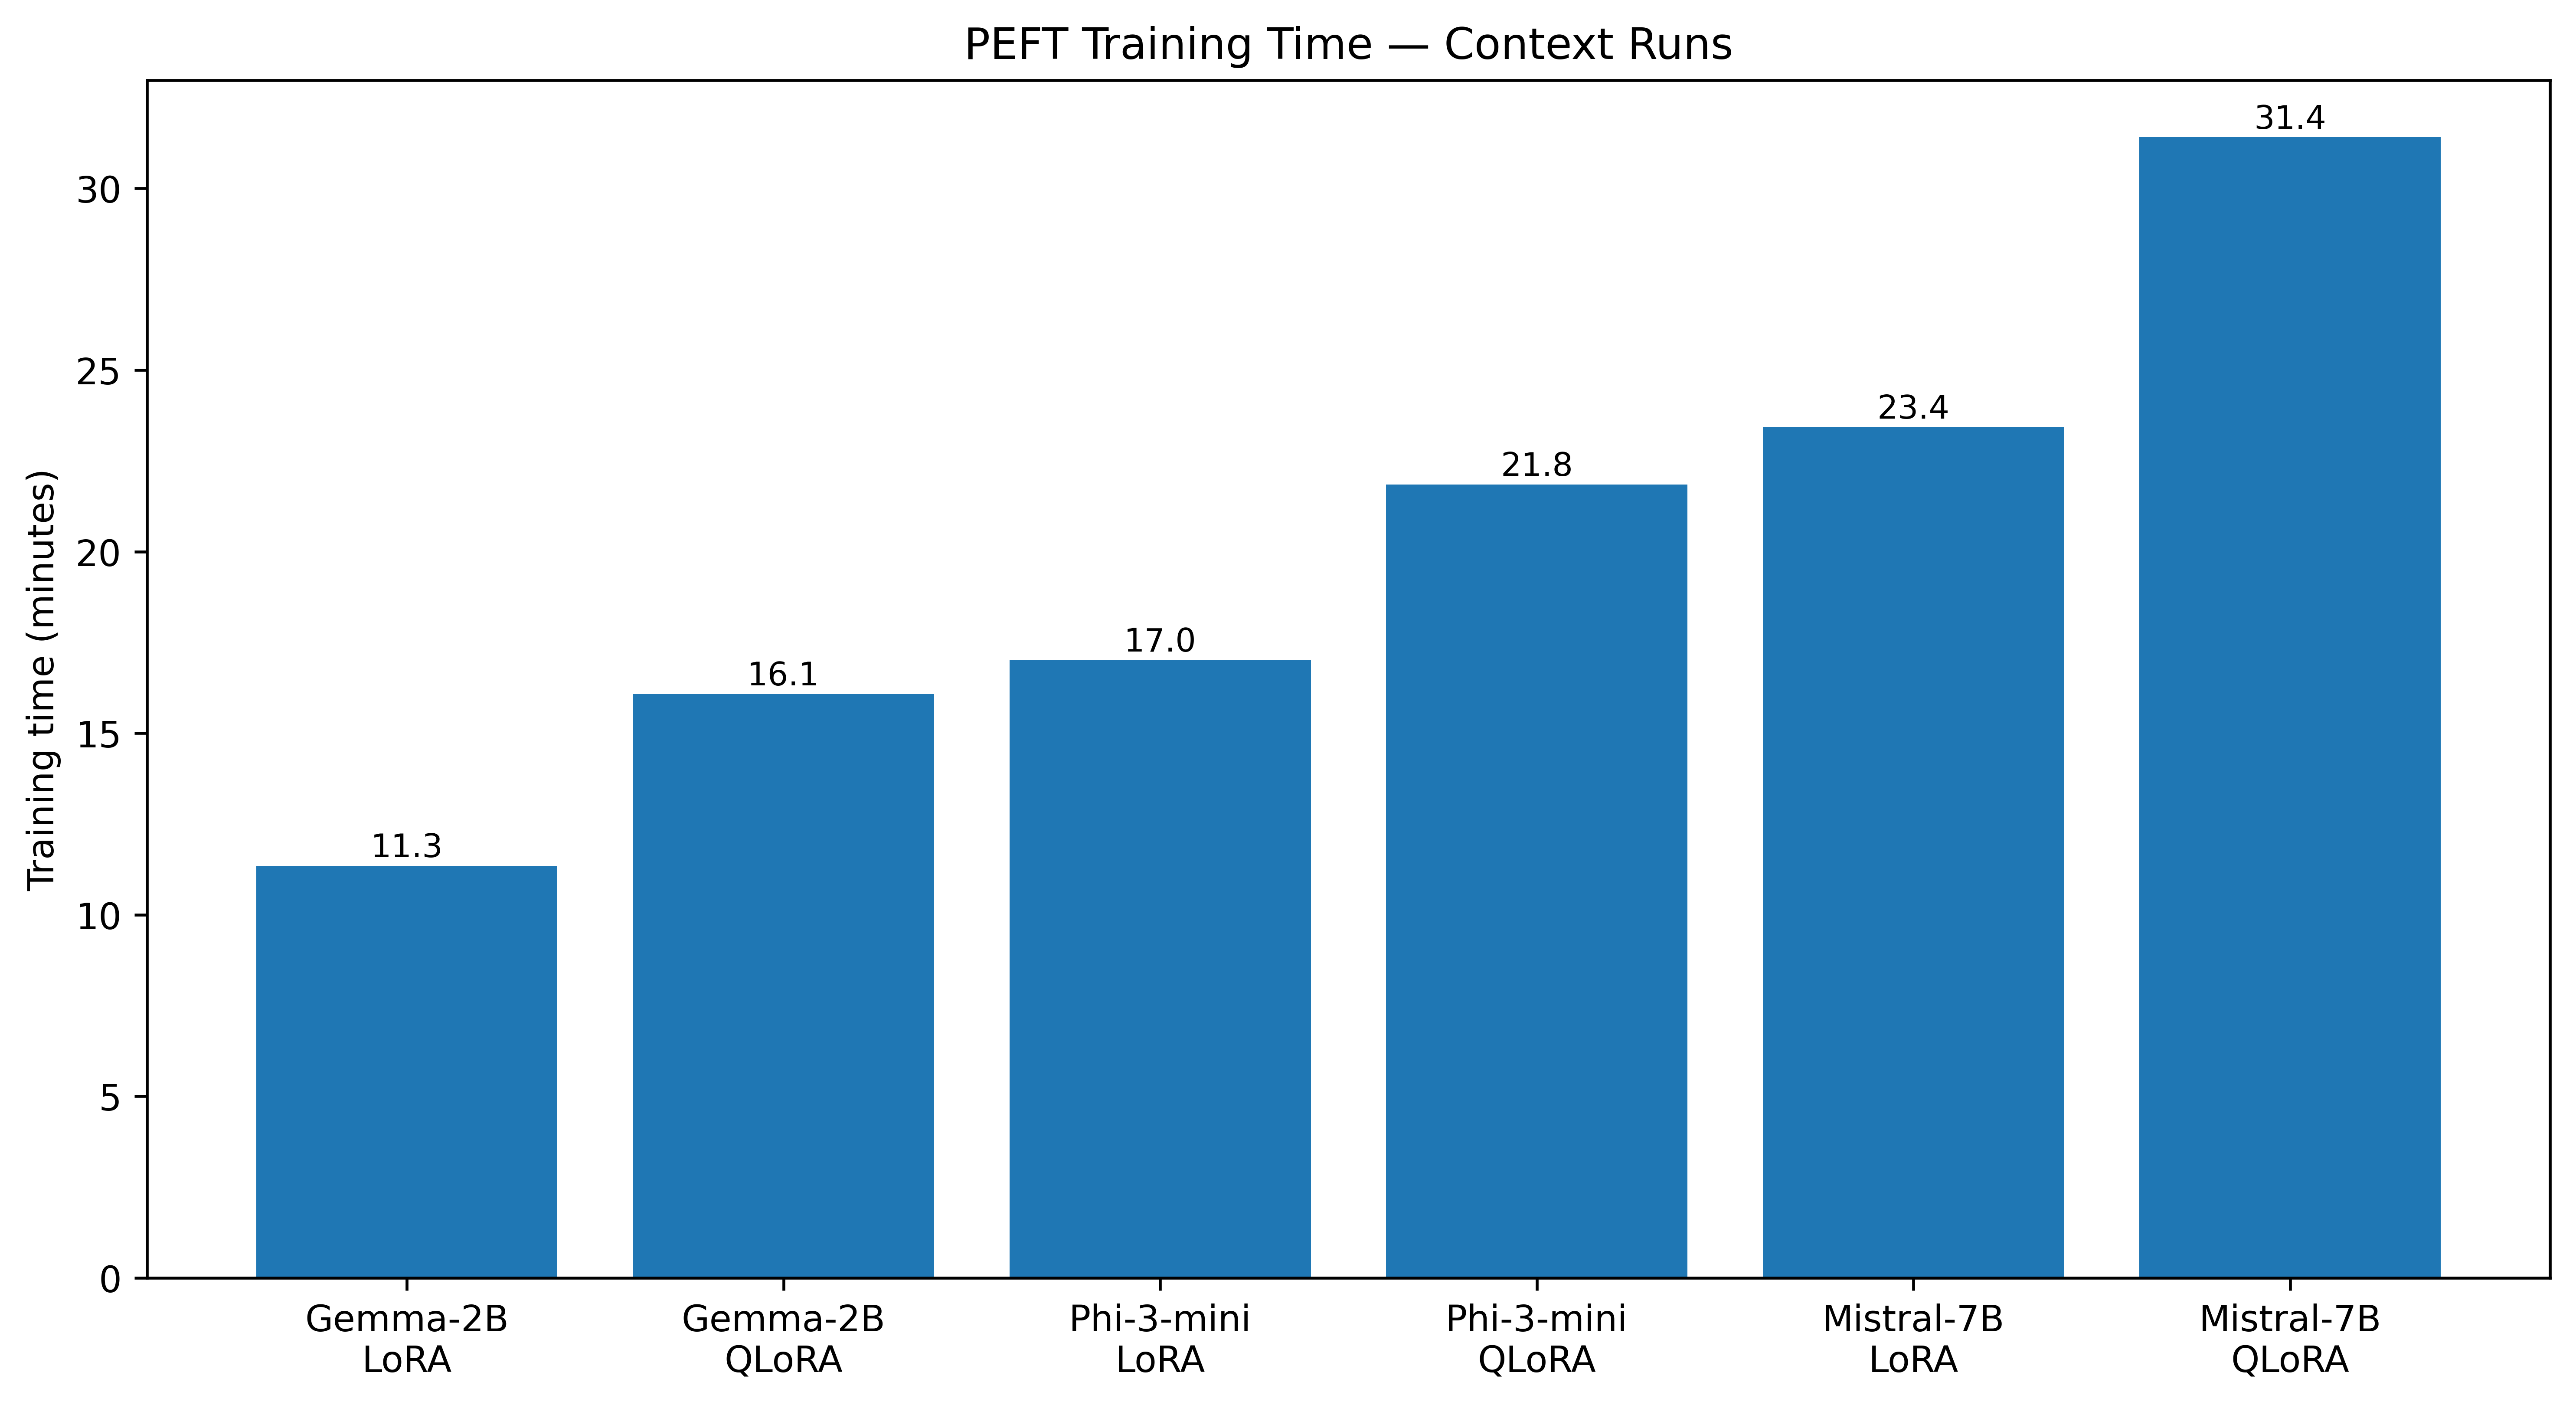

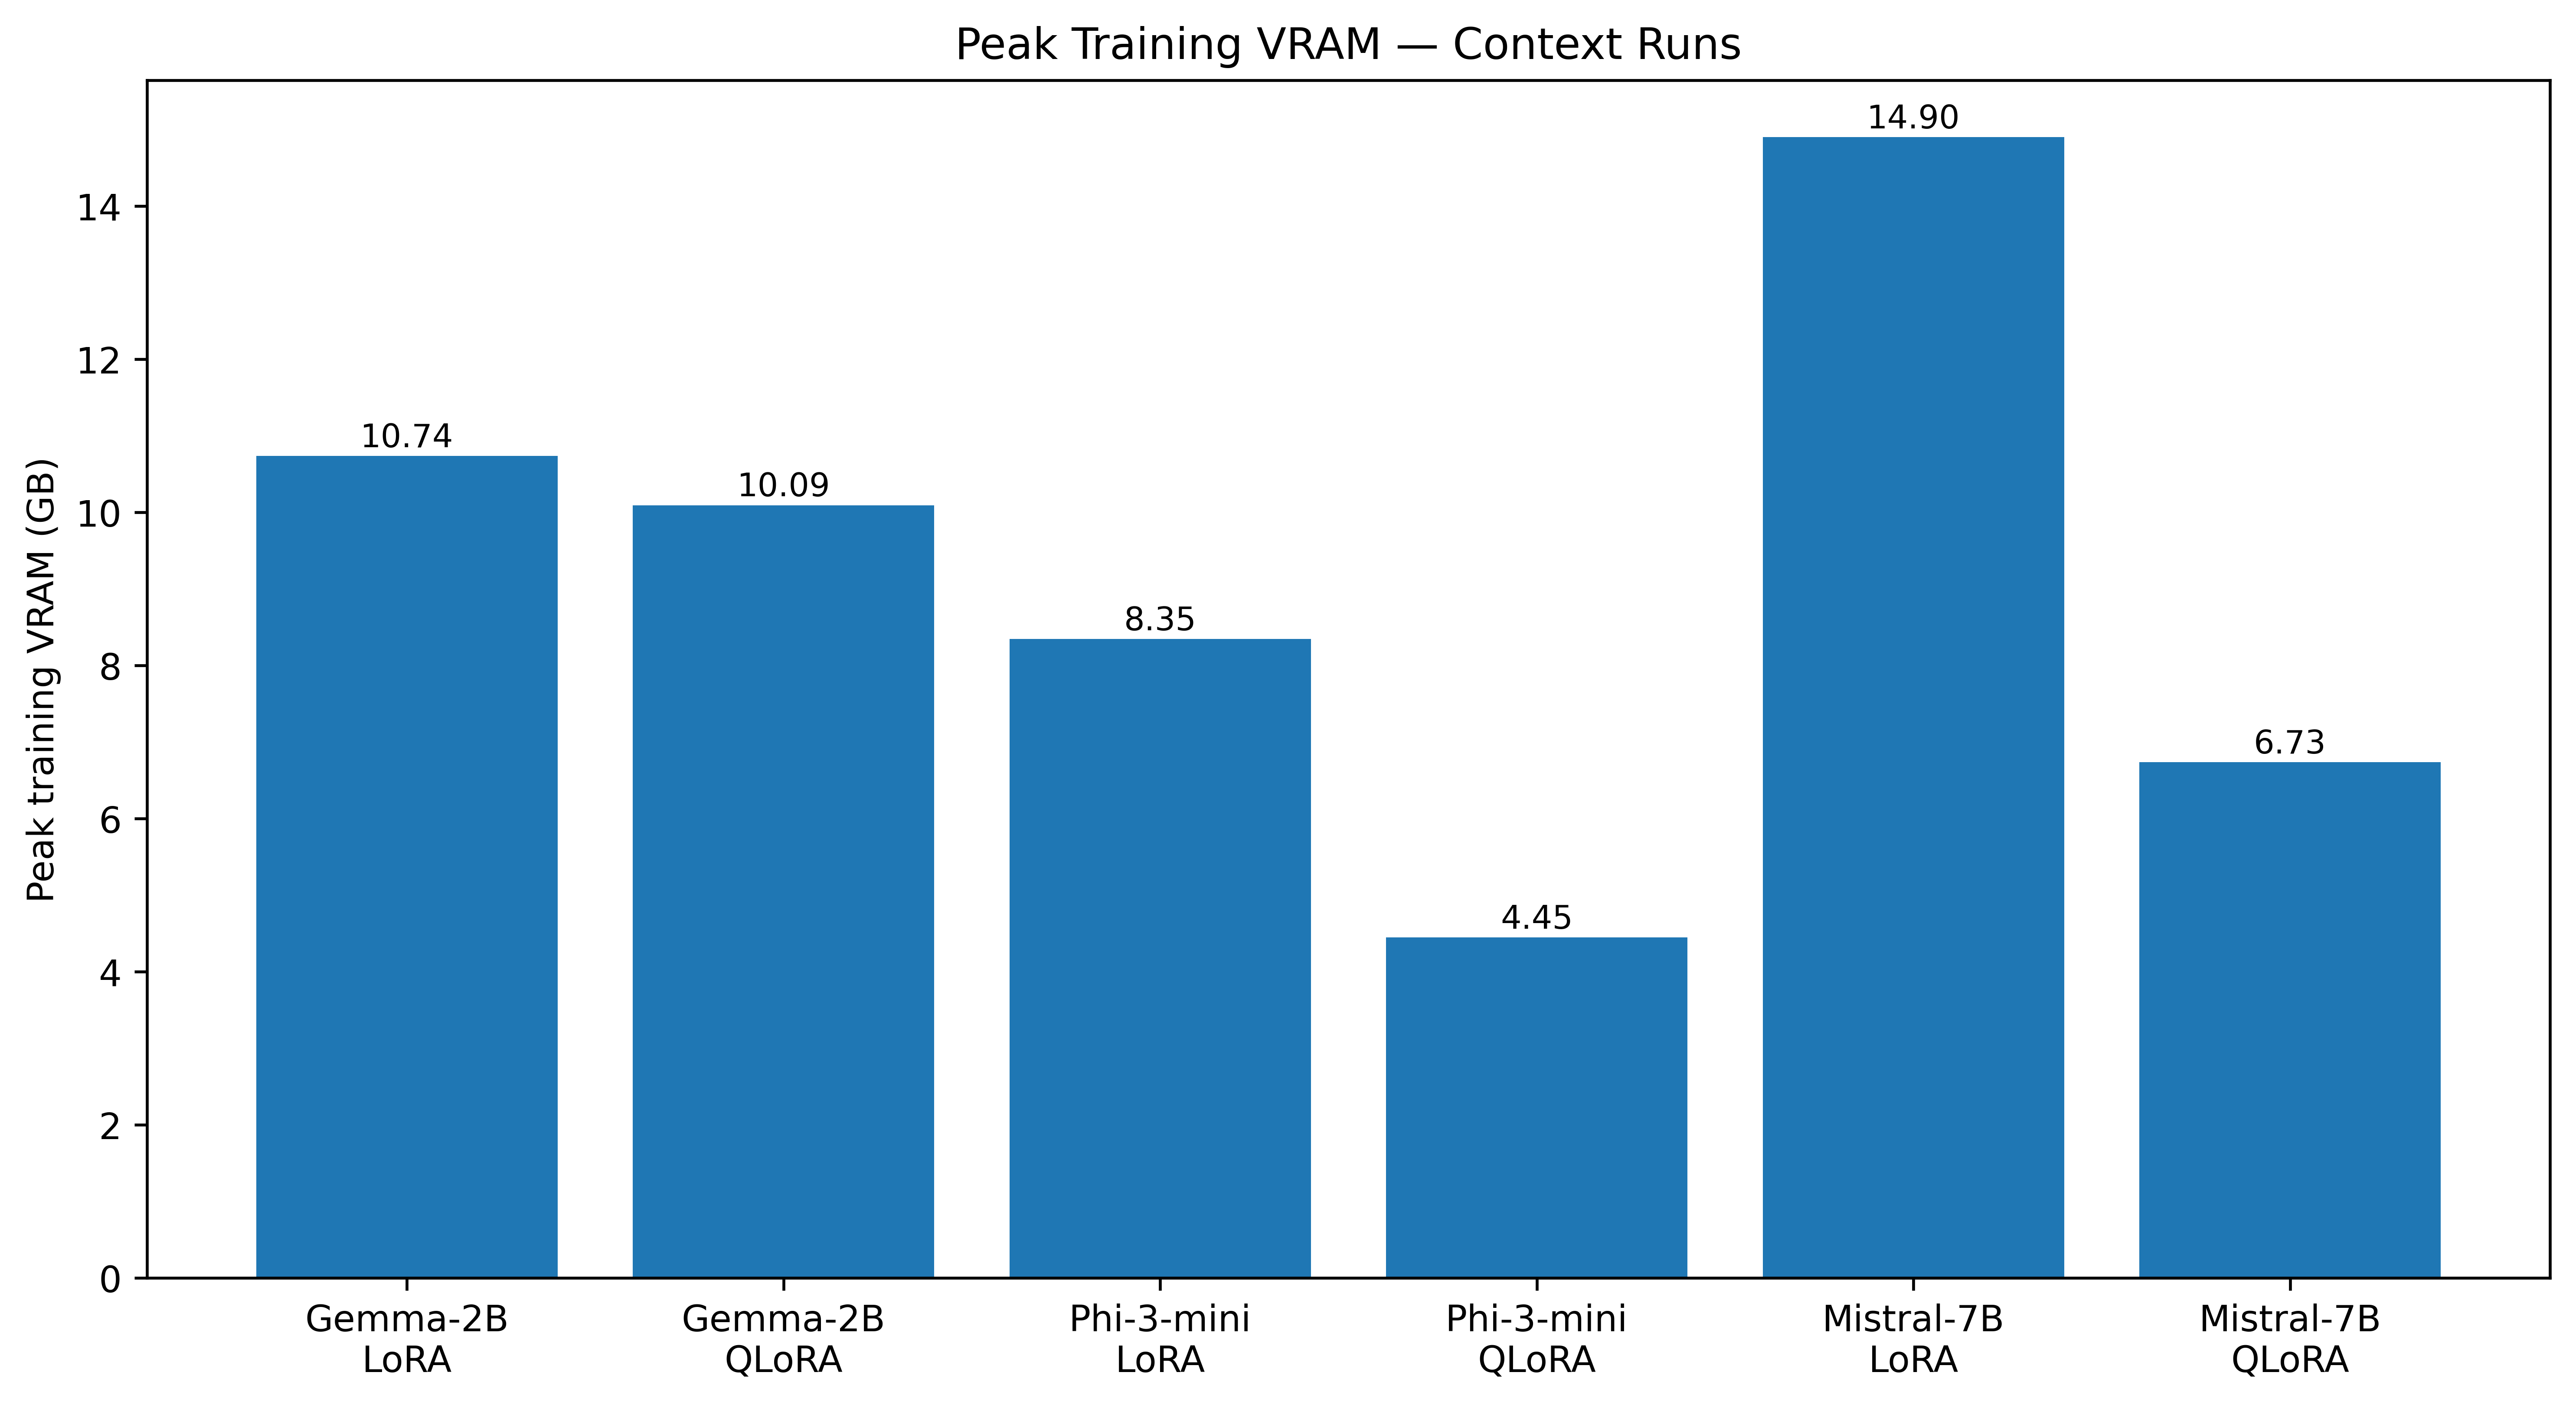

Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ3_Training_Time_All6.png
Saved: /content/drive/MyDrive/MR603_Thesis/results/cross_model_context/figures/RQ3_Peak_Training_VRAM_All6.png


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 15 — TRAINING TIME + NEW TRAINING VRAM FIGURES
# Training VRAM is descriptive only and is NOT added to the
# old Pareto/composite formula.
# ═══════════════════════════════════════════════════════════

d = all_results.sort_values(
    ["Parameters_B", "Method"]
).copy()

labels = (
    d["Model"]
    + "\n"
    + d["Method"]
)

# Training time
fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

x = np.arange(
    len(d)
)

bars = ax.bar(
    x,
    d["Training_Time_min"]
)

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.set_ylabel(
    "Training time (minutes)"
)

ax.set_title(
    "PEFT Training Time — Context Runs"
)

for bar, value in zip(
    bars,
    d["Training_Time_min"]
):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.25,
        f"{value:.1f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

TRAIN_TIME_FIG = (
    f"{FIGURE_DIR}/"
    "RQ3_Training_Time_All6.png"
)

plt.savefig(
    TRAIN_TIME_FIG,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# Peak training VRAM — new complete comparison
fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

bars = ax.bar(
    x,
    d["Peak_Train_VRAM_GB"]
)

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.set_ylabel(
    "Peak training VRAM (GB)"
)

ax.set_title(
    "Peak Training VRAM — Context Runs"
)

for bar, value in zip(
    bars,
    d["Peak_Train_VRAM_GB"]
):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.12,
        f"{value:.2f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

TRAIN_VRAM_FIG = (
    f"{FIGURE_DIR}/"
    "RQ3_Peak_Training_VRAM_All6.png"
)

plt.savefig(
    TRAIN_VRAM_FIG,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", TRAIN_TIME_FIG)
print("Saved:", TRAIN_VRAM_FIG)

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 16 — STRATEGY-LEVEL LoRA VS QLoRA AGGREGATES
# ═══════════════════════════════════════════════════════════

strategy_summary = (
    all_results.groupby(
        "Method",
        as_index=False
    )
    .agg(
        Mean_F1_percent=(
            "F1_percent",
            "mean"
        ),
        Mean_EM_percent=(
            "EM_percent",
            "mean"
        ),
        Mean_Training_Time_min=(
            "Training_Time_min",
            "mean"
        ),
        Mean_Latency_ms=(
            "Avg_Latency_ms",
            "mean"
        ),
        Mean_Eval_VRAM_GB=(
            "Peak_Eval_VRAM_GB",
            "mean"
        ),
        Mean_Train_VRAM_GB=(
            "Peak_Train_VRAM_GB",
            "mean"
        )
    )
)

print("=" * 78)
print("STRATEGY-LEVEL AGGREGATES")
print("=" * 78)

display(
    strategy_summary.round(3)
)

strategy_summary.to_csv(
    f"{FINAL_DIR}/Strategy_Level_Aggregates.csv",
    index=False
)

# Paired differences by architecture
paired = (
    all_results.pivot(
        index="Model",
        columns="Method",
        values=[
            "F1_percent",
            "Training_Time_min",
            "Avg_Latency_ms",
            "Peak_Eval_VRAM_GB",
            "Peak_Train_VRAM_GB"
        ]
    )
)

paired.columns = [
    f"{metric}_{method}"
    for metric, method
    in paired.columns
]

paired = paired.reset_index()

paired["Delta_F1_LoRA_minus_QLoRA"] = (
    paired["F1_percent_LoRA"]
    -
    paired["F1_percent_QLoRA"]
)

paired["Delta_Latency_QLoRA_minus_LoRA_ms"] = (
    paired["Avg_Latency_ms_QLoRA"]
    -
    paired["Avg_Latency_ms_LoRA"]
)

paired["Delta_Eval_VRAM_QLoRA_minus_LoRA_GB"] = (
    paired["Peak_Eval_VRAM_GB_QLoRA"]
    -
    paired["Peak_Eval_VRAM_GB_LoRA"]
)

paired["Delta_Train_VRAM_QLoRA_minus_LoRA_GB"] = (
    paired["Peak_Train_VRAM_GB_QLoRA"]
    -
    paired["Peak_Train_VRAM_GB_LoRA"]
)

print("\nPaired architecture-level differences:")

display(
    paired.round(3)
)

paired.to_csv(
    f"{FINAL_DIR}/LoRA_vs_QLoRA_Paired_Differences.csv",
    index=False
)

STRATEGY-LEVEL AGGREGATES


,Method,Mean_F1_percent,Mean_EM_percent,Mean_Training_Time_min,Mean_Latency_ms,Mean_Eval_VRAM_GB,Mean_Train_VRAM_GB
0,LoRA,18.941,0.03,17.256,3361.159,8.748,11.327
1,QLoRA,18.901,0.00,23.112,4764.016,3.850,7.091



Paired architecture-level differences:


,Model,F1_percent_LoRA,F1_percent_QLoRA,Training_Time_min_LoRA,Training_Time_min_QLoRA,Avg_Latency_ms_LoRA,Avg_Latency_ms_QLoRA,Peak_Eval_VRAM_GB_LoRA,Peak_Eval_VRAM_GB_QLoRA,Peak_Train_VRAM_GB_LoRA,Peak_Train_VRAM_GB_QLoRA,Delta_F1_LoRA_minus_QLoRA,Delta_Latency_QLoRA_minus_LoRA_ms,Delta_Eval_VRAM_QLoRA_minus_LoRA_GB,Delta_Train_VRAM_QLoRA_minus_LoRA_GB
0,Gemma-2B,17.309,17.263,11.342,16.083,2410.089,3619.289,5.121,3.321,10.737,10.092,0.047,1209.200,-1.801,-0.645
1,Mistral-7B,19.483,19.357,23.419,31.409,4117.590,6328.417,13.701,4.991,14.897,6.733,0.125,2210.827,-8.709,-8.164
2,Phi-3-mini,20.030,20.084,17.008,21.845,3555.800,4344.341,7.421,3.237,8.346,4.448,-0.053,788.541,-4.184,-3.899


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 17 — MODEL-SCALE DESCRIPTIVE ANALYSIS
# For each architecture, selects the stronger observed F1
# condition only for describing scale-related gains.
# ═══════════════════════════════════════════════════════════

scale_best = (
    all_results.sort_values(
        "F1_percent",
        ascending=False
    )
    .groupby(
        "Model",
        as_index=False
    )
    .first()
)

scale_best = scale_best.sort_values(
    "Parameters_B"
).reset_index(drop=True)

scale_best["F1_Gain_from_Previous_Scale_pp"] = (
    scale_best["F1_percent"].diff()
)

scale_best["Parameter_Increase_B"] = (
    scale_best["Parameters_B"].diff()
)

scale_best["F1_Gain_per_Additional_B"] = (
    scale_best["F1_Gain_from_Previous_Scale_pp"]
    /
    scale_best["Parameter_Increase_B"]
)

print("=" * 78)
print("DESCRIPTIVE MODEL-SCALE COMPARISON")
print("=" * 78)

display(
    scale_best[
        [
            "Model",
            "Parameters_B",
            "Method",
            "F1_percent",
            "F1_Gain_from_Previous_Scale_pp",
            "Parameter_Increase_B",
            "F1_Gain_per_Additional_B"
        ]
    ].round(3)
)

scale_best.to_csv(
    f"{FINAL_DIR}/Model_Scale_Descriptive_Analysis.csv",
    index=False
)

print(
    "\nThis is a descriptive comparison of observed results, "
    "not a causal estimate of parameter scaling."
)

DESCRIPTIVE MODEL-SCALE COMPARISON


,Model,Parameters_B,Method,F1_percent,F1_Gain_from_Previous_Scale_pp,Parameter_Increase_B,F1_Gain_per_Additional_B
0,Gemma-2B,2.0,LoRA,17.309,NaN,NaN,NaN
1,Phi-3-mini,3.8,QLoRA,20.084,2.775,1.8,1.541
2,Mistral-7B,7.0,LoRA,19.483,-0.601,3.2,-0.188



This is a descriptive comparison of observed results, not a causal estimate of parameter scaling.


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 18 — FINAL RQ SUMMARY
# Findings are generated directly from the corrected data.
# ═══════════════════════════════════════════════════════════

best_f1 = rq1.iloc[0]

largest_qtype = (
    rq2_ranked.iloc[0]
)

pareto_models = (
    pareto_view[
        pareto_view[
            "Pareto_Efficient"
        ]
    ]
)

best_composite = (
    score.iloc[0]
)

above_zero = int(
    (
        rq1[
            "F1_percent"
        ]
        >
        QWEN_ZERO_F1
    ).sum()
)

above_two = int(
    (
        rq1[
            "F1_percent"
        ]
        >
        QWEN_TWO_F1
    ).sum()
)

summary = pd.DataFrame([
    {
        "RQ":
            "RQ1",
        "Finding":
            (
                f'Highest corrected SLM F1 was '
                f'{best_f1["Model"]} {best_f1["Method"]} '
                f'({best_f1["F1_percent"]:.3f}%). '
                f'Qwen zero-shot + context was {QWEN_ZERO_F1:.3f}% '
                f'and Qwen 2-shot + context was {QWEN_TWO_F1:.3f}%. '
                f'{above_zero}/6 SLM conditions exceeded zero-shot; '
                f'{above_two}/6 exceeded 2-shot.'
            )
    },
    {
        "RQ":
            "RQ2",
        "Finding":
            (
                f'Largest absolute observed LoRA–QLoRA F1 difference '
                f'occurred for {largest_qtype["Model"]}, '
                f'{largest_qtype["Question_Type"]}: '
                f'{largest_qtype["Delta_F1_LoRA_minus_QLoRA"]:+.3f} '
                f'percentage points.'
            )
    },
    {
        "RQ":
            "RQ3",
        "Finding":
            (
                f'{len(pareto_models)} of 6 corrected PEFT conditions '
                f'were Pareto-efficient under F1, latency and '
                f'evaluation VRAM. Under the secondary 50/25/25 '
                f'weighting, the highest composite score was '
                f'{best_composite["Model"]} {best_composite["Method"]} '
                f'({best_composite["Deployment_Composite_Score"]:.2f}/100).'
            )
    }
])

print("=" * 84)
print("FINAL RESEARCH-QUESTION SUMMARY")
print("=" * 84)

display(summary)

summary.to_csv(
    f"{FINAL_DIR}/Final_RQ_Summary.csv",
    index=False
)

FINAL RESEARCH-QUESTION SUMMARY


,RQ,Finding
0,RQ1,Highest corrected SLM F1 was Phi-3-mini QLoRA ...
1,RQ2,Largest absolute observed LoRA–QLoRA F1 differ...
2,RQ3,4 of 6 corrected PEFT conditions were Pareto-e...


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 19 — FINAL CROSS-MODEL DASHBOARD
# ═══════════════════════════════════════════════════════════

dashboard = all_results[
    [
        "Model",
        "Method",
        "Parameters_B",
        "EM_percent",
        "F1_percent",
        "Training_Time_min",
        "Avg_Latency_ms",
        "Peak_Eval_VRAM_GB",
        "Peak_Train_VRAM_GB"
    ]
].copy()

dashboard = dashboard.merge(
    pareto[
        [
            "Model",
            "Method",
            "Pareto_Efficient"
        ]
    ],
    on=[
        "Model",
        "Method"
    ],
    how="left"
)

dashboard = dashboard.merge(
    score[
        [
            "Model",
            "Method",
            "Deployment_Composite_Score",
            "Composite_Rank"
        ]
    ],
    on=[
        "Model",
        "Method"
    ],
    how="left"
)

dashboard[
    "F1_Gap_to_Qwen_ZeroShot_pp"
] = (
    dashboard["F1_percent"]
    -
    QWEN_ZERO_F1
)

dashboard[
    "F1_Gap_to_Qwen_2Shot_pp"
] = (
    dashboard["F1_percent"]
    -
    QWEN_TWO_F1
)

dashboard = dashboard.sort_values(
    "F1_percent",
    ascending=False
).reset_index(drop=True)

print("=" * 92)
print("FINAL CORRECTED CROSS-MODEL DASHBOARD")
print("=" * 92)

display(
    dashboard.round(3)
)

dashboard.to_csv(
    f"{FINAL_DIR}/Final_CrossModel_Dashboard.csv",
    index=False
)

FINAL CORRECTED CROSS-MODEL DASHBOARD


,Model,Method,Parameters_B,EM_percent,F1_percent,Training_Time_min,Avg_Latency_ms,Peak_Eval_VRAM_GB,Peak_Train_VRAM_GB,Pareto_Efficient,Deployment_Composite_Score,Composite_Rank,F1_Gap_to_Qwen_ZeroShot_pp,F1_Gap_to_Qwen_2Shot_pp
0,Phi-3-mini,QLoRA,3.8,0.000,20.084,21.845,4344.341,3.237,4.448,True,87.659,1,2.292,1.150
1,Phi-3-mini,LoRA,3.8,0.091,20.030,17.008,3555.800,7.421,8.346,True,81.746,2,2.239,1.097
2,Mistral-7B,LoRA,7.0,0.000,19.483,23.419,4117.590,13.701,14.897,False,53.450,4,1.691,0.549
3,Mistral-7B,QLoRA,7.0,0.000,19.357,31.409,6328.417,4.991,6.733,False,57.933,3,1.566,0.424
4,Gemma-2B,LoRA,2.0,0.000,17.309,11.342,2410.089,5.121,10.737,True,46.325,5,-0.483,-1.624
5,Gemma-2B,QLoRA,2.0,0.000,17.263,16.083,3619.289,3.321,10.092,True,42.086,6,-0.529,-1.671


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 20 — SAVE QWEN REFERENCE TABLE + FINAL MANIFEST
# ═══════════════════════════════════════════════════════════

qwen_refs.to_csv(
    f"{FINAL_DIR}/Qwen_Context_Reference_Comparison.csv",
    index=False
)

manifest = {
    "analysis":
        "Final corrected cross-model comparison",
    "source_mode":
        "BM25-retrieved syllabus context",
    "dataset":
        "SyllabusQA",
    "split": {
        "train": 3018,
        "validation": 957,
        "test": 1103
    },
    "six_peft_conditions": [
        "R5_Gemma2B_LoRA_CONTEXT",
        "R6_Gemma2B_QLoRA_CONTEXT",
        "R1_Phi3Mini_LoRA_CONTEXT",
        "R2_Phi3Mini_QLoRA_CONTEXT",
        "R3_Mistral7B_LoRA_CONTEXT",
        "R4_Mistral7B_QLoRA_CONTEXT"
    ],
    "references": [
        "Qwen2.5-14B Zero-Shot + Context",
        "Qwen2.5-14B 2-Shot + Context"
    ],
    "primary_metrics": [
        "token-level F1",
        "Exact Match",
        "average inference latency",
        "peak evaluation VRAM"
    ],
    "adaptation_metrics": [
        "training time",
        "peak training VRAM"
    ],
    "pareto_dimensions": [
        "maximize F1",
        "minimize inference latency",
        "minimize evaluation VRAM"
    ],
    "composite_weights": {
        "F1": 0.50,
        "latency_efficiency": 0.25,
        "evaluation_vram_efficiency": 0.25
    }
}

with open(
    f"{FINAL_DIR}/CrossModel_CONTEXT_Manifest.json",
    "w"
) as f:
    json.dump(
        manifest,
        f,
        indent=2
    )

print("✓ Qwen reference table saved.")
print("✓ Analysis manifest saved.")

✓ Qwen reference table saved.
✓ Analysis manifest saved.


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 21 — FINAL OUTPUT VERIFICATION
# ═══════════════════════════════════════════════════════════

required_outputs = [
    "All_Six_SLM_Conditions.csv",
    "RQ1_Final_Comparison.csv",
    "RQ2_All_Models_Native_QuestionTypes.csv",
    "RQ2_Model_Level_Summary.csv",
    "RQ3_Raw_Comparison.csv",
    "RQ3_Pareto_Analysis.csv",
    "RQ3_Deployment_Composite_Score.csv",
    "Strategy_Level_Aggregates.csv",
    "LoRA_vs_QLoRA_Paired_Differences.csv",
    "Model_Scale_Descriptive_Analysis.csv",
    "Final_RQ_Summary.csv",
    "Final_CrossModel_Dashboard.csv",
    "Qwen_Context_Reference_Comparison.csv",
    "CrossModel_CONTEXT_Manifest.json"
]

expected_figures = [
    "RQ1_F1_vs_Qwen_Context.png",
    "RQ2_DeltaF1_Heatmap.png",
    "RQ2_Gemma_2B_F1.png",
    "RQ2_Phi_3_mini_F1.png",
    "RQ2_Mistral_7B_F1.png",
    "RQ3_F1_vs_Latency.png",
    "RQ3_F1_vs_EvalVRAM.png",
    "RQ3_Training_Time_All6.png",
    "RQ3_Peak_Training_VRAM_All6.png"
]

print("=" * 86)
print("FINAL CROSS-MODEL CONTEXT ANALYSIS CHECK")
print("=" * 86)

ok = True

for filename in required_outputs:

    path = f"{FINAL_DIR}/{filename}"

    exists = os.path.exists(path)

    print(
        f"{'FOUND' if exists else 'MISSING':7s} "
        f"{filename}"
    )

    ok &= exists

print("\nFigures:")

for filename in expected_figures:

    path = f"{FIGURE_DIR}/{filename}"

    exists = os.path.exists(path)

    print(
        f"{'FOUND' if exists else 'MISSING':7s} "
        f"{filename}"
    )

    ok &= exists

if ok:

    print("\n" + "=" * 72)
    print("✓ FINAL CORRECTED CROSS-MODEL IMPLEMENTATION COMPLETE")
    print("✓ Six corrected PEFT conditions validated")
    print("✓ Qwen zero-shot + context included")
    print("✓ Qwen 2-shot + context included")
    print("✓ RQ1 / RQ2 / RQ3 outputs complete")
    print("✓ Pareto + secondary composite regenerated")
    print("✓ Training VRAM descriptive comparison added")
    print("=" * 72)

else:

    print(
        "\nDo not freeze the notebook yet — "
        "one or more outputs are missing."
    )

FINAL CROSS-MODEL CONTEXT ANALYSIS CHECK
FOUND   All_Six_SLM_Conditions.csv
FOUND   RQ1_Final_Comparison.csv
FOUND   RQ2_All_Models_Native_QuestionTypes.csv
FOUND   RQ2_Model_Level_Summary.csv
FOUND   RQ3_Raw_Comparison.csv
FOUND   RQ3_Pareto_Analysis.csv
FOUND   RQ3_Deployment_Composite_Score.csv
FOUND   Strategy_Level_Aggregates.csv
FOUND   LoRA_vs_QLoRA_Paired_Differences.csv
FOUND   Model_Scale_Descriptive_Analysis.csv
FOUND   Final_RQ_Summary.csv
FOUND   Final_CrossModel_Dashboard.csv
FOUND   Qwen_Context_Reference_Comparison.csv
FOUND   CrossModel_CONTEXT_Manifest.json

Figures:
FOUND   RQ1_F1_vs_Qwen_Context.png
FOUND   RQ2_DeltaF1_Heatmap.png
FOUND   RQ2_Gemma_2B_F1.png
FOUND   RQ2_Phi_3_mini_F1.png
FOUND   RQ2_Mistral_7B_F1.png
FOUND   RQ3_F1_vs_Latency.png
FOUND   RQ3_F1_vs_EvalVRAM.png
FOUND   RQ3_Training_Time_All6.png
FOUND   RQ3_Peak_Training_VRAM_All6.png

✓ FINAL CORRECTED CROSS-MODEL IMPLEMENTATION COMPLETE
✓ Six corrected PEFT conditions validated
✓ Qwen zero-shot + c

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("/content/figures_600dpi", 'zip', FIGURE_DIR)
files.download("/content/figures_600dpi.zip")
print("Done — check your browser downloads folder")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done — check your browser downloads folder


## Interpretation guardrails for thesis

Use the outputs generated as the single corrected cross-model source.

- Treating token-level F1 as the primary QA metric and report EM separately.
- Qwen zero-shot + context and Qwen 2-shot + context are larger prompting references, not fine-tuning-matched controls.
- Pareto analysis is based only on F1, inference latency, and peak evaluation VRAM, matching the earlier cross-comparison methodology.
- Peak training VRAM is included descriptively because it is available for all six corrected runs, but it is not silently added to the old Pareto or 50/25/25 composite formula.
- The 50/25/25 composite is a secondary decision aid whose ordering depends on the stated weights.
- The model-scale cell is descriptive and should not be presented as a causal scaling law.